# Avance 1 y Avance 3: exploración y análisis de clientes

**Proyecto integrador - InsightReach**

En este notebook desarrollo el análisis de la base de clientes. Primero reviso su estructura y calidad, y luego filtro Miami para conocer mejor a sus clientes. En el Avance 3 amplío el análisis a las diez ciudades de la base, respondo las preguntas de negocio con tablas y gráficos y, por último, profundizo en Miami para integrar la información obtenida de Yelp.

La consulta a Yelp devolvió **100 negocios**. Utilizo los 100 para describir la muestra obtenida y separo los **83 negocios cuya localidad informada es Miami** cuando hago comparaciones específicas con los clientes de esa ciudad. La integración es contextual: no existe un identificador común que permita unir cada cliente con un restaurante concreto.

**Nota sobre el gasto:** la base contiene `frecuencia_visita` y `promedio_gasto_comida`, pero no especifica el período de la frecuencia ni la moneda del gasto. Por eso, cuando calculo `frecuencia_visita × promedio_gasto_comida`, lo llamo *gasto estimado por período registrado*. No lo presento como gasto mensual confirmado. Solo podría interpretarse como mensual si se confirma que la frecuencia está expresada en visitas por mes.


## 1. Importo las librerías

Uso pandas para trabajar con las tablas, numpy para algunas operaciones numéricas y matplotlib y seaborn para hacer los gráficos.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")
sns.set_theme(style="whitegrid")

print("Librerías cargadas correctamente.")


Librerías cargadas correctamente.


## 2. Cargo los archivos

Cargo la base anonimizada de clientes y los dos archivos CSV que preparé a partir de la consulta real a Yelp: uno contiene los datos generales de los negocios y el otro sus categorías. Primero exploro la base de clientes y después uso Yelp para complementar el análisis de la oferta gastronómica de Miami.

In [2]:
def encontrar_carpeta_datos():
    rutas_posibles = [
        Path("Datos"), Path("../Datos"), Path("../../Datos"),
        Path("../../../Datos"), Path("/content/Datos"),
    ]
    for ruta in rutas_posibles:
        if ruta.is_dir():
            return ruta
    ruta = Path("Datos")
    ruta.mkdir(parents=True, exist_ok=True)
    return ruta

carpeta_datos = encontrar_carpeta_datos()


def buscar_archivo(nombre_archivo):
    rutas_posibles = [
        Path(nombre_archivo), carpeta_datos / nombre_archivo,
        Path("../Datos") / nombre_archivo, Path("../../Datos") / nombre_archivo,
        Path("../../../Datos") / nombre_archivo,
        Path("/content") / nombre_archivo, Path("/content/Datos") / nombre_archivo,
        Path("/mnt/data") / nombre_archivo,
    ]
    for ruta in rutas_posibles:
        if ruta.exists():
            return ruta
    try:
        from google.colab import files
        print(f"No encontré {nombre_archivo}. Seleccionalo para subirlo.")
        archivos_subidos = files.upload()
        if nombre_archivo in archivos_subidos:
            return Path("/content") / nombre_archivo
    except ImportError:
        pass
    raise FileNotFoundError(
        f"No encontré {nombre_archivo}. Guardalo en la carpeta Datos o subilo a Colab."
    )

ruta_clientes = buscar_archivo("base_clientes_sin_datos_contacto.csv")
ruta_yelp = buscar_archivo("yelp_miami_consulta_api.csv")
ruta_categorias = buscar_archivo("yelp_miami_categorias.csv")

df_original = pd.read_csv(ruta_clientes)
df_yelp_original = pd.read_csv(ruta_yelp)
df_yelp_categorias_original = pd.read_csv(ruta_categorias)

print("Base de clientes:", df_original.shape)
print("Negocios obtenidos de Yelp API:", df_yelp_original.shape)
print("Relaciones negocio-categoría:", df_yelp_categorias_original.shape)

Base de clientes: (30000, 13)
Negocios obtenidos de Yelp API: (100, 13)
Relaciones negocio-categoría: (202, 4)


## 3. Miro cómo viene la base

Antes de filtrar o limpiar, reviso los nombres de las columnas, los tipos de datos y algunas filas para entender qué información tengo.

In [3]:
print("Nombres de las columnas:")
print(df_original.columns.tolist())

print("\nTipos de datos y cantidad de valores completos:")
df_original.info()

columnas_personales = [
    "id_persona", "nombre", "apellido",
    "telefono_contacto", "correo_electronico"
]
columnas_para_mostrar = [
    columna for columna in df_original.columns
    if columna not in columnas_personales
]

display(df_original[columnas_para_mostrar].head())

print("\nResumen de las columnas numéricas:")
display(df_original.select_dtypes(include=np.number).describe().T)


Nombres de las columnas:
['id_persona', 'edad', 'genero', 'ciudad_residencia', 'estrato_socioeconomico', 'frecuencia_visita', 'promedio_gasto_comida', 'ocio', 'consume_licor', 'preferencias_alimenticias', 'membresia_premium', 'tipo_de_pago_mas_usado', 'ingresos_mensuales']

Tipos de datos y cantidad de valores completos:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 30000 entries, 0 to 29999
Data columns (total 13 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   id_persona                 30000 non-null  object 
 1   edad                       29899 non-null  float64
 2   genero                     30000 non-null  object 
 3   ciudad_residencia          30000 non-null  object 
 4   estrato_socioeconomico     30000 non-null  object 
 5   frecuencia_visita          30000 non-null  int64  
 6   promedio_gasto_comida      29855 non-null  float64
 7   ocio                       30000 non-null  object 
 8   con

,edad,genero,ciudad_residencia,estrato_socioeconomico,frecuencia_visita,promedio_gasto_comida,ocio,consume_licor,preferencias_alimenticias,membresia_premium,tipo_de_pago_mas_usado,ingresos_mensuales
0,31.00,Masculino,Miami,Alto,6,67.51,Sí,No,Vegetariano,Sí,Efectivo,6425
1,40.00,Femenino,Denver,Medio,2,44.92,Sí,Sí,Mariscos,No,Efectivo,2374
2,62.00,Femenino,Denver,Bajo,2,9.24,Sí,Sí,Vegetariano,No,Efectivo,1110
3,41.00,Masculino,Boston,Alto,5,30.74,Sí,Sí,Carnes,Sí,Tarjeta,6931
4,49.00,Femenino,San Diego,Bajo,0,0.00,No,No,Carnes,No,Tarjeta,1350



Resumen de las columnas numéricas:


,count,mean,std,min,25%,50%,75%,max
edad,"29,899.00",49.67,23.84,-5.00,33.00,49.00,65.00,300.00
frecuencia_visita,"30,000.00",3.90,2.74,-3.00,2.00,4.00,5.00,10.00
promedio_gasto_comida,"29,855.00",32.60,26.40,0.00,13.29,25.51,44.40,149.97
ingresos_mensuales,"30,000.00","5,389.76","4,538.49",800.00,"1,860.00","3,402.00","7,761.00","17,999.00"


### 3.1. ¿Qué representa cada fila?

Cada fila corresponde a una persona. Hay datos generales, como edad, género, ciudad y estrato socioeconómico, y otros sobre sus hábitos: frecuencia de visita, gasto promedio, preferencias alimenticias, membresía y medio de pago.

## 4. Reviso si hay datos repetidos o faltantes

Primero cuento las filas duplicadas y los IDs repetidos. También reviso en qué columnas faltan datos y en qué cantidad.

In [4]:
duplicados_completos = df_original.duplicated().sum()
ids_repetidos = df_original["id_persona"].duplicated().sum()

print("Filas completamente repetidas:", duplicados_completos)
print("IDs de persona repetidos:", ids_repetidos)

resumen_faltantes = pd.DataFrame({
    "cantidad_faltante": df_original.isna().sum(),
    "porcentaje_faltante": (df_original.isna().mean() * 100).round(2)
})
resumen_faltantes = resumen_faltantes.sort_values(
    "porcentaje_faltante", ascending=False
)
display(resumen_faltantes)


Filas completamente repetidas: 0
IDs de persona repetidos: 0


,cantidad_faltante,porcentaje_faltante
preferencias_alimenticias,1403,4.68
promedio_gasto_comida,145,0.48
edad,101,0.34
id_persona,0,0.00
genero,0,0.00
estrato_socioeconomico,0,0.00
ciudad_residencia,0,0.00
ocio,0,0.00
frecuencia_visita,0,0.00
consume_licor,0,0.00


### 4.1. Busco valores que no parecen correctos

Además de los valores faltantes, reviso algunos datos que podrían ser errores de carga. Una edad negativa o una frecuencia de visita negativa no parecen válidas. En cambio, dejo las frecuencias iguales a cero porque podrían indicar que esa persona no visitó restaurantes durante el período registrado.

In [5]:
controles = pd.DataFrame({
    "control": [
        "Edades menores que 0",
        "Edades mayores que 100",
        "Frecuencias de visita negativas",
        "Gastos promedio negativos",
        "Ingresos mensuales iguales o menores que 0"
    ],
    "cantidad": [
        (df_original["edad"] < 0).sum(),
        (df_original["edad"] > 100).sum(),
        (df_original["frecuencia_visita"] < 0).sum(),
        (df_original["promedio_gasto_comida"] < 0).sum(),
        (df_original["ingresos_mensuales"] <= 0).sum()
    ]
})
display(controles)

print("\nValores de algunas columnas de texto:")
for columna in [
    "genero", "ciudad_residencia", "estrato_socioeconomico",
    "preferencias_alimenticias", "membresia_premium", "tipo_de_pago_mas_usado"
]:
    print(columna, ":", sorted(df_original[columna].dropna().astype(str).str.strip().unique()))


,control,cantidad
0,Edades menores que 0,97
1,Edades mayores que 100,110
2,Frecuencias de visita negativas,1547
3,Gastos promedio negativos,0
4,Ingresos mensuales iguales o menores que 0,0



Valores de algunas columnas de texto:
genero : ['Femenino', 'Masculino']
ciudad_residencia : ['Boston', 'Chicago', 'Dallas', 'Denver', 'Houston', 'Miami', 'NYC', 'Phoenix', 'San Diego', 'Seattle']
estrato_socioeconomico : ['Alto', 'Bajo', 'Medio', 'Muy Alto']
preferencias_alimenticias : ['Carnes', 'Mariscos', 'Otro', 'Pescado', 'Vegano', 'Vegetariano']
membresia_premium : ['No', 'Sí']
tipo_de_pago_mas_usado : ['App', 'Criptomoneda', 'Efectivo', 'Tarjeta']


## 5. Elijo la ciudad para seguir trabajando

Elegí **Miami** porque hay clientes residentes en esa ciudad y la consulta a Yelp se realizó usando `Miami, FL` como ubicación. La búsqueda devolvió también algunos negocios de localidades cercanas, algo que puede pasar al buscar por una zona geográfica. Más adelante separo los que tienen `city = Miami` para comparar una misma localidad.

In [6]:
clientes_por_ciudad = (
    df_original["ciudad_residencia"].astype("string").str.strip()
    .value_counts().rename_axis("ciudad").reset_index(name="cantidad_clientes")
)
clientes_por_ciudad["porcentaje"] = (
    clientes_por_ciudad["cantidad_clientes"] / len(df_original) * 100
).round(2)
display(clientes_por_ciudad)

ciudades_clientes = set(
    df_original["ciudad_residencia"].dropna().astype(str).str.strip().str.casefold()
)
ciudades_yelp = set(
    df_yelp_original["city"].dropna().astype(str).str.strip().str.casefold()
)
ciudades_en_comun = sorted(ciudades_clientes.intersection(ciudades_yelp))
print("Localidades informadas por Yelp que también aparecen en la base de clientes:", ciudades_en_comun)

CIUDAD_OBJETIVO = "Miami"
df_ciudad_original = df_original[
    df_original["ciudad_residencia"].astype(str).str.strip().str.casefold()
    == CIUDAD_OBJETIVO.casefold()
].copy()

print("\nCiudad elegida:", CIUDAD_OBJETIVO)
print("Clientes de esa ciudad:", len(df_ciudad_original))
print("Porcentaje de la base completa:", round(len(df_ciudad_original) / len(df_original) * 100, 2), "%")

,ciudad,cantidad_clientes,porcentaje
0,Chicago,5384,17.95
1,NYC,4769,15.90
2,Miami,3186,10.62
3,San Diego,3075,10.25
4,Dallas,2602,8.67
5,Boston,2547,8.49
6,Denver,2523,8.41
7,Houston,2212,7.37
8,Seattle,2191,7.30
9,Phoenix,1511,5.04


Localidades informadas por Yelp que también aparecen en la base de clientes: ['miami']

Ciudad elegida: Miami
Clientes de esa ciudad: 3186
Porcentaje de la base completa: 10.62 %


## 6. Limpio los datos de Miami

Trabajo con una copia de los registros de Miami para no modificar el archivo original. Después reviso los textos y los campos numéricos.

- No encontré filas duplicadas ni IDs repetidos.
- Las edades menores que 0 o mayores que 100 las marco como faltantes.
- Hago lo mismo con las frecuencias negativas.
- Mantengo las frecuencias iguales a cero.
- No completo los datos que faltan, porque no tengo forma de saber cuál sería el valor correcto.

In [7]:
df_limpio = df_ciudad_original.copy()

# Quito espacios al principio y al final de las columnas de texto.
for columna in df_limpio.select_dtypes(include="object").columns:
    df_limpio[columna] = df_limpio[columna].astype("string").str.strip()

# Me aseguro de que estas columnas sean numéricas.
columnas_numericas = [
    "edad", "frecuencia_visita",
    "promedio_gasto_comida", "ingresos_mensuales"
]
for columna in columnas_numericas:
    df_limpio[columna] = pd.to_numeric(df_limpio[columna], errors="coerce")

filas_antes = len(df_limpio)
df_limpio = df_limpio.drop_duplicates().copy()
duplicados_eliminados = filas_antes - len(df_limpio)

# Marco como faltantes los valores que no son posibles o no sirven para el análisis.
edad_invalida = (df_limpio["edad"] < 0) | (df_limpio["edad"] > 100)
frecuencia_invalida = df_limpio["frecuencia_visita"] < 0
gasto_invalido = df_limpio["promedio_gasto_comida"] < 0

cantidad_edades_invalidas = int(edad_invalida.sum())
cantidad_frecuencias_invalidas = int(frecuencia_invalida.sum())
cantidad_gastos_invalidos = int(gasto_invalido.sum())

df_limpio.loc[edad_invalida, "edad"] = np.nan
df_limpio.loc[frecuencia_invalida, "frecuencia_visita"] = np.nan
df_limpio.loc[gasto_invalido, "promedio_gasto_comida"] = np.nan

print("Filas duplicadas eliminadas:", duplicados_eliminados)
print("Clientes que quedaron en Miami:", len(df_limpio))
print("Edades fuera del rango elegido:", cantidad_edades_invalidas)
print("Frecuencias negativas:", cantidad_frecuencias_invalidas)
print("Gastos negativos:", cantidad_gastos_invalidos)

# Para las tablas y los gráficos dejo afuera los datos personales.
columnas_personales = [
    "id_persona", "nombre", "apellido",
    "telefono_contacto", "correo_electronico"
]
df_analisis = df_limpio.drop(columns=columnas_personales, errors="ignore").copy()

display(df_analisis.head())


Filas duplicadas eliminadas: 0
Clientes que quedaron en Miami: 3186
Edades fuera del rango elegido: 28
Frecuencias negativas: 173
Gastos negativos: 0


,edad,genero,ciudad_residencia,estrato_socioeconomico,frecuencia_visita,promedio_gasto_comida,ocio,consume_licor,preferencias_alimenticias,membresia_premium,tipo_de_pago_mas_usado,ingresos_mensuales
0,31.00,Masculino,Miami,Alto,6.00,67.51,Sí,No,Vegetariano,Sí,Efectivo,6425
16,18.00,Masculino,Miami,Muy Alto,9.00,26.60,Sí,Sí,Vegetariano,Sí,App,13452
37,79.00,Femenino,Miami,Muy Alto,6.00,28.43,No,No,Mariscos,Sí,Efectivo,14072
45,76.00,Masculino,Miami,Alto,5.00,43.00,Sí,No,Mariscos,Sí,App,6528
47,55.00,Masculino,Miami,Muy Alto,5.00,119.85,Sí,No,Carnes,Sí,Efectivo,15844


## 7. Reviso cómo quedó la base

Vuelvo a contar los valores faltantes y compruebo que no hayan quedado filas duplicadas. Mantengo los registros aunque tengan algún dato vacío, así no pierdo información que sí puede servir para otras partes del análisis.

In [8]:
resumen_despues = pd.DataFrame({
    "tipo_de_dato": df_limpio.dtypes.astype(str),
    "faltantes": df_limpio.isna().sum(),
    "porcentaje_faltante": (df_limpio.isna().mean() * 100).round(2)
})
display(resumen_despues.sort_values("faltantes", ascending=False))

print("Dimensiones después de la limpieza:", df_limpio.shape)
print("Duplicados completos que quedan:", df_limpio.duplicated().sum())
print("IDs únicos:", df_limpio["id_persona"].nunique())


,tipo_de_dato,faltantes,porcentaje_faltante
frecuencia_visita,float64,173,5.43
preferencias_alimenticias,string,146,4.58
edad,float64,36,1.13
promedio_gasto_comida,float64,16,0.50
id_persona,string,0,0.00
estrato_socioeconomico,string,0,0.00
ciudad_residencia,string,0,0.00
genero,string,0,0.00
ocio,string,0,0.00
consume_licor,string,0,0.00


Dimensiones después de la limpieza: (3186, 13)


Duplicados completos que quedan: 0
IDs únicos: 3186


## 8. Algunas tablas para conocer a los clientes

Miro la distribución de las variables principales y algunos valores promedio. En las tablas de categorías incluyo la cantidad y el porcentaje sobre el total de clientes de Miami.

In [9]:
# Resumen de edad, frecuencia, gasto e ingresos.
display(df_analisis[[
    "edad", "frecuencia_visita",
    "promedio_gasto_comida", "ingresos_mensuales"
]].describe().T.round(2))

# Esta función arma una tabla sencilla de cantidades y porcentajes.
def tabla_frecuencias(dataframe, columna):
    cantidades = dataframe[columna].value_counts(dropna=False)
    tabla = cantidades.rename("cantidad").to_frame()
    tabla["porcentaje"] = (tabla["cantidad"] / len(dataframe) * 100).round(2)
    return tabla

for columna in [
    "genero", "estrato_socioeconomico", "preferencias_alimenticias",
    "membresia_premium", "tipo_de_pago_mas_usado", "consume_licor", "ocio"
]:
    print("\nDistribución de", columna)
    display(tabla_frecuencias(df_limpio, columna))


,count,mean,std,min,25%,50%,75%,max
edad,"3,150.00",49.08,17.89,18.00,34.00,49.00,65.00,80.00
frecuencia_visita,"3,013.00",4.78,2.28,0.00,3.00,5.00,6.00,10.00
promedio_gasto_comida,"3,170.00",39.82,28.34,0.00,19.16,31.60,54.00,129.50
ingresos_mensuales,"3,186.00","6,476.26","4,823.68",800.00,"2,449.50","5,206.00","9,042.00","17,998.00"



Distribución de genero


,cantidad,porcentaje
genero,,
Masculino,1615,50.69
Femenino,1571,49.31



Distribución de estrato_socioeconomico


,cantidad,porcentaje
estrato_socioeconomico,,
Alto,1159,36.38
Muy Alto,799,25.08
Medio,783,24.58
Bajo,445,13.97



Distribución de preferencias_alimenticias


... (5 outputs left out)


Distribución de consume_licor


,cantidad,porcentaje
consume_licor,,
Sí,1911,59.98
No,1275,40.02



Distribución de ocio


,cantidad,porcentaje
ocio,,
Sí,1602,50.28
No,1584,49.72


### 8.1. Comparo los datos por estrato

También comparo cantidad de clientes, ingresos, gasto, frecuencia y membresía premium entre los distintos estratos. Quería ver si aparecían diferencias entre los grupos.

In [10]:
tabla_estrato = (
    df_limpio.groupby("estrato_socioeconomico", dropna=False)
    .agg(
        clientes=("id_persona", "count"),
        ingreso_mensual_promedio=("ingresos_mensuales", "mean"),
        gasto_promedio=("promedio_gasto_comida", "mean"),
        frecuencia_promedio=("frecuencia_visita", "mean"),
        porcentaje_premium=("membresia_premium", lambda x: (x == "Sí").mean() * 100)
    )
    .sort_values("clientes", ascending=False)
    .round(2)
)
display(tabla_estrato)

# También miro el gasto promedio según la frecuencia que quedó registrada.
tabla_frecuencia_gasto = (
    df_limpio.groupby("frecuencia_visita", dropna=True)
    .agg(
        clientes=("id_persona", "count"),
        gasto_medio=("promedio_gasto_comida", "mean")
    )
    .round(2)
)
display(tabla_frecuencia_gasto)


,clientes,ingreso_mensual_promedio,gasto_promedio,frecuencia_promedio,porcentaje_premium
estrato_socioeconomico,,,,,
Alto,1159,"6,198.78",40.10,5.00,70.32
Muy Alto,799,"13,660.96",68.77,7.51,95.62
Medio,783,"2,557.81",24.89,3.51,14.56
Bajo,445,"1,193.47",13.34,1.53,0.22


,clientes,gasto_medio
frecuencia_visita,,
0.00,102,0.00
1.00,103,16.95
2.00,272,21.92
3.00,319,21.54
4.00,531,35.24
5.00,714,42.30
6.00,464,47.04
7.00,125,74.05
8.00,128,66.01


## 9. Hago algunos gráficos

Con los gráficos puedo ver las distribuciones más rápido y comparar algunas variables. Debajo anoto lo que me llamó la atención.

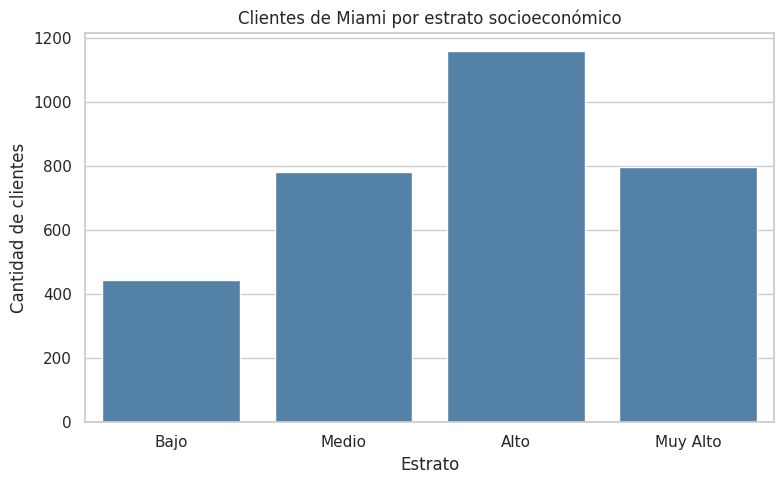

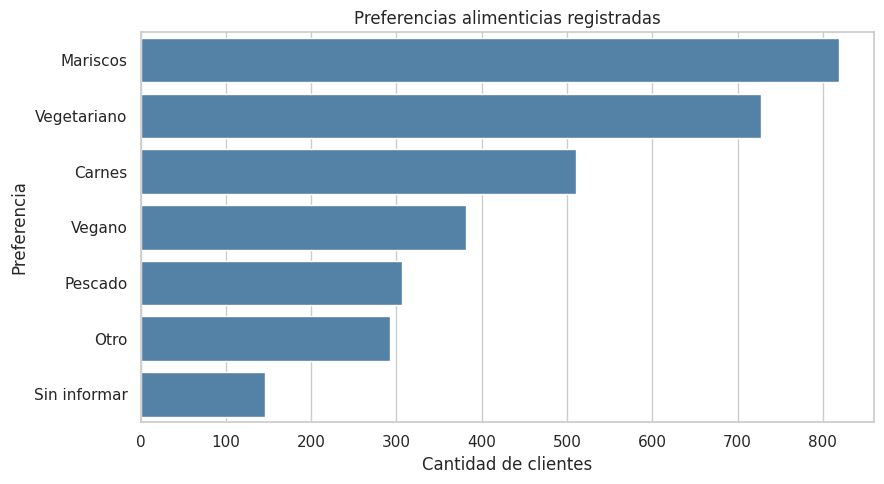

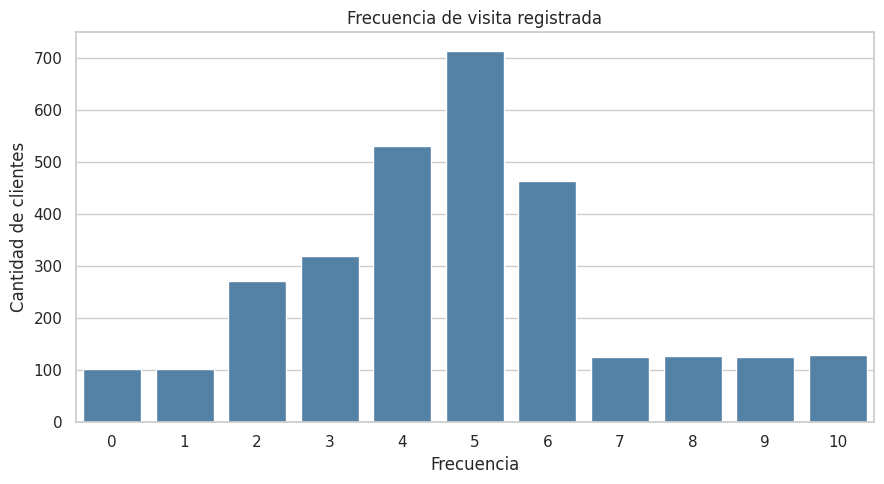

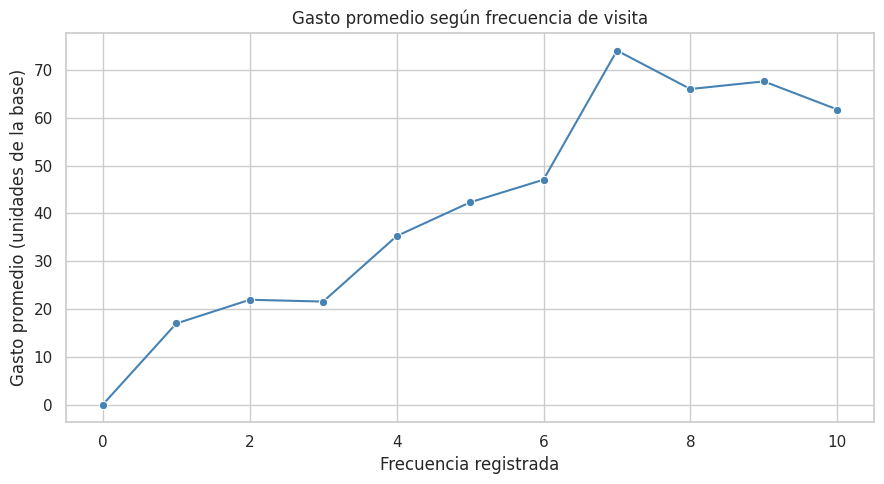

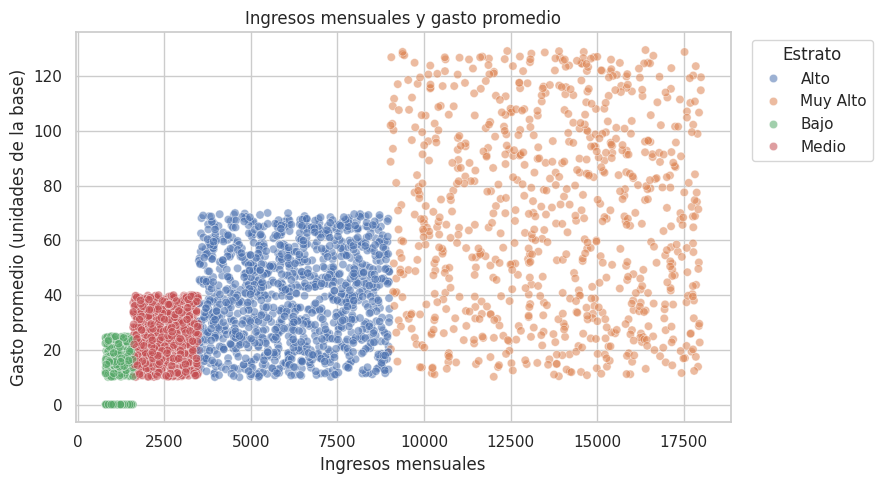

In [11]:
# 1. Cantidad de clientes por estrato.
orden_estratos = ["Bajo", "Medio", "Alto", "Muy Alto"]
orden_presentes = [
    x for x in orden_estratos
    if x in df_limpio["estrato_socioeconomico"].dropna().unique()
]
plt.figure(figsize=(8, 5))
sns.countplot(data=df_limpio, x="estrato_socioeconomico", order=orden_presentes, color="steelblue")
plt.title("Clientes de Miami por estrato socioeconómico")
plt.xlabel("Estrato")
plt.ylabel("Cantidad de clientes")
plt.tight_layout()
plt.show()

# 2. Preferencias alimenticias. Los faltantes aparecen como "Sin informar".
preferencias_grafico = (
    df_limpio["preferencias_alimenticias"]
    .fillna("Sin informar")
    .value_counts()
)
plt.figure(figsize=(9, 5))
sns.barplot(x=preferencias_grafico.values, y=preferencias_grafico.index, color="steelblue")
plt.title("Preferencias alimenticias registradas")
plt.xlabel("Cantidad de clientes")
plt.ylabel("Preferencia")
plt.tight_layout()
plt.show()

# 3. Frecuencia de visita. Los valores negativos ya se pasaron a faltantes.
plt.figure(figsize=(9, 5))
sns.countplot(x=df_limpio["frecuencia_visita"].dropna().astype(int), color="steelblue")
plt.title("Frecuencia de visita registrada")
plt.xlabel("Frecuencia")
plt.ylabel("Cantidad de clientes")
plt.tight_layout()
plt.show()

# 4. Gasto promedio según frecuencia registrada.
gasto_por_frecuencia = (
    df_limpio.dropna(subset=["frecuencia_visita"])
    .groupby("frecuencia_visita")["promedio_gasto_comida"]
    .mean()
    .reset_index()
)
plt.figure(figsize=(9, 5))
sns.lineplot(
    data=gasto_por_frecuencia,
    x="frecuencia_visita", y="promedio_gasto_comida", marker="o", color="steelblue"
)
plt.title("Gasto promedio según frecuencia de visita")
plt.xlabel("Frecuencia registrada")
plt.ylabel("Gasto promedio (unidades de la base)")
plt.tight_layout()
plt.show()

# 5. Ingresos y gasto promedio.
datos_scatter = df_limpio.dropna(subset=["ingresos_mensuales", "promedio_gasto_comida"])
plt.figure(figsize=(9, 5))
sns.scatterplot(
    data=datos_scatter,
    x="ingresos_mensuales", y="promedio_gasto_comida",
    hue="estrato_socioeconomico", alpha=0.55
)
plt.title("Ingresos mensuales y gasto promedio")
plt.xlabel("Ingresos mensuales")
plt.ylabel("Gasto promedio (unidades de la base)")
plt.legend(title="Estrato", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()


### 9.1. Qué observé en los gráficos

- En Miami hay más clientes de estrato **Alto** y **Muy Alto**. Juntos representan cerca del 61,5% de los registros.
- Las preferencias que más aparecen son **Mariscos** y **Vegetariano**. También hay personas que no informaron una preferencia.
- La frecuencia que más se repite es 5. El archivo no dice si se refiere a una semana, un mes u otro período.
- En general, el gasto medio es mayor entre quienes tienen una frecuencia de visita más alta.
- También aparece una relación positiva entre ingresos y gasto. Esto no quiere decir que una variable sea la causa de la otra.

## 10. Reviso la relación entre algunas variables

Calculo la correlación entre las variables numéricas para ver cuáles tienden a aumentar o disminuir juntas. La correlación sirve como referencia, pero no demuestra una relación de causa y efecto.

,edad,frecuencia_visita,promedio_gasto_comida,ingresos_mensuales
edad,1.00,-0.02,-0.00,-0.02
frecuencia_visita,-0.02,1.00,0.56,0.77
promedio_gasto_comida,-0.00,0.56,1.00,0.63
ingresos_mensuales,-0.02,0.77,0.63,1.00


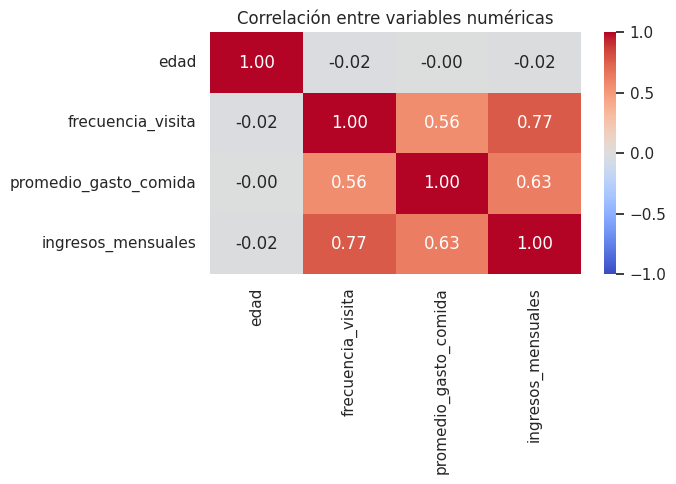

In [12]:
variables_correlacion = [
    "edad", "frecuencia_visita",
    "promedio_gasto_comida", "ingresos_mensuales"
]
matriz_correlacion = df_limpio[variables_correlacion].corr(numeric_only=True)
display(matriz_correlacion.round(2))

plt.figure(figsize=(7, 5))
sns.heatmap(
    matriz_correlacion, annot=True, cmap="coolwarm",
    center=0, vmin=-1, vmax=1, fmt=".2f"
)
plt.title("Correlación entre variables numéricas")
plt.tight_layout()
plt.show()


## 11. Reviso los datos obtenidos de Yelp

La consulta a la API devolvió 100 negocios únicos. Primero reviso la muestra completa: localidades, calificaciones, reseñas, distancia, precios y categorías. Después identifico los 83 negocios cuya ciudad informada es exactamente Miami para hacer una comparación geográfica más precisa con los clientes de esa ciudad.

In [13]:
print("Negocios recibidos de la API:", len(df_yelp_original))
print("IDs únicos:", df_yelp_original["id"].nunique())
print("Relaciones negocio-categoría guardadas:", len(df_yelp_categorias_original))
print("Pares negocio-categoría únicos:", df_yelp_categorias_original[["id", "alias"]].drop_duplicates().shape[0])

print("\nDistribución de negocios por localidad:")
display(df_yelp_original["city"].value_counts().rename_axis("localidad").to_frame("negocios"))

print("\nEstadísticas generales de los 100 negocios recibidos:")
display(df_yelp_original[["rating", "review_count", "distance_km"]].describe().T.round(2))

print("\nNiveles de precio informados para los 100 negocios:")
display(df_yelp_original["price"].fillna("No especificado").value_counts().to_frame("negocios"))

Negocios recibidos de la API: 100
IDs únicos: 100
Relaciones negocio-categoría guardadas: 202
Pares negocio-categoría únicos: 202

Distribución de negocios por localidad:


,negocios
localidad,
Miami,83
Coral Gables,11
Doral,4
Coral Terrace,1
Kendall,1



Estadísticas generales de los 100 negocios recibidos:


,count,mean,std,min,25%,50%,75%,max
rating,100.00,4.38,0.32,3.60,4.10,4.40,4.60,5.00
review_count,100.00,686.80,"1,107.22",4.00,93.75,269.50,792.50,"7,100.00"
distance_km,100.00,5.79,2.94,0.77,3.20,5.27,7.48,12.80



Niveles de precio informados para los 100 negocios:


,negocios
price,
Medio,41
No especificado,39
Alto,16
Bajo,3
Muy Alto,1


## 12. Conclusiones del Avance 1

Después de revisar la base, decidí seguir trabajando con **Miami**. Allí hay 3.186 clientes, aproximadamente el 10,6% de las 30.000 personas de la base original.

Lo que más me llamó la atención fue lo siguiente:

- La distribución por género está bastante pareja: alrededor de 51% Masculino y 49% Femenino.
- Los estratos Alto y Muy Alto reúnen cerca del 61,5% de los clientes.
- La edad mediana es de 49 años. El gasto promedio registrado es de unas 39,82 unidades de la base y la frecuencia media válida es 4,78.
- Las preferencias más frecuentes son Mariscos y Vegetariano. Hay 146 registros sin preferencia informada.
- Encontré 28 edades fuera del rango de 0 a 100 y 173 frecuencias negativas. Las marqué como faltantes, pero mantuve a esas personas en la base.
- No encontré filas duplicadas ni IDs repetidos.
- La correlación entre ingresos y gasto es de aproximadamente 0,63. Entre frecuencia y gasto es de alrededor de 0,56.
- La consulta realizada a Yelp devolvió 100 negocios. En el Avance 3 reviso esta muestra completa y separo los 83 negocios cuya ciudad informada es Miami para hacer una comparación más precisa con los clientes de esa ciudad.

Hay dos datos que el archivo no aclara: el período al que corresponde la frecuencia y la moneda del gasto. Tampoco puedo saber qué restaurante visita cada persona. Por eso, la información de Yelp la uso como referencia general de Miami.

Con esta revisión ya tengo una base para seguir trabajando en los otros avances.

In [14]:
# Algunos números para dejar registrados
print(f"Base original: {len(df_original):,} clientes")
print(f"Clientes de Miami: {len(df_limpio):,}")
print(f"Porcentaje de Miami sobre la base: {len(df_limpio) / len(df_original) * 100:.2f}%")
print(f"Edad mediana: {df_limpio['edad'].median():.0f} años")
print(f"Frecuencia media válida: {df_limpio['frecuencia_visita'].mean():.2f}")
print(f"Gasto promedio: {df_limpio['promedio_gasto_comida'].mean():.2f} unidades de la base")
print(f"Clientes de estrato Alto o Muy Alto: {df_limpio['estrato_socioeconomico'].isin(['Alto', 'Muy Alto']).mean() * 100:.1f}%")
print(f"Clientes con membresía premium: {df_limpio['membresia_premium'].eq('Sí').mean() * 100:.1f}%")
print(f"Preferencia alimenticia sin informar: {df_limpio['preferencias_alimenticias'].isna().mean() * 100:.1f}%")


Base original: 30,000 clientes
Clientes de Miami: 3,186
Porcentaje de Miami sobre la base: 10.62%
Edad mediana: 49 años
Frecuencia media válida: 4.78
Gasto promedio: 39.82 unidades de la base
Clientes de estrato Alto o Muy Alto: 61.5%
Clientes con membresía premium: 53.2%
Preferencia alimenticia sin informar: 4.6%


# Avance 3: análisis integrado y segmentación

En este avance analizo la base completa para comparar las diez ciudades y también mantengo un análisis más detallado de Miami, que fue la ciudad elegida para la consulta a Yelp. La fuente externa utilizada en este proyecto es Yelp: sus categorías, calificaciones, reseñas y precios aportan contexto sobre la oferta gastronómica local.

Primero respondo las preguntas generales de la consigna con la base de 30.000 clientes. Después retomo Miami para segmentar a sus clientes y comparar sus preferencias con los 100 negocios obtenidos de Yelp (mostrando aparte los 83 con ciudad informada Miami).


## 13. Preguntas que quiero responder

Para cubrir la consigna, primero miro la base completa:

1. ¿Cuántos clientes hay en cada ciudad?
2. ¿Cómo se distribuyen los clientes por estrato socioeconómico?
3. ¿Qué ciudades presentan un mayor gasto estimado por período registrado?
4. ¿Cómo se relacionan la frecuencia de visita y el gasto promedio por comida dentro de cada estrato?
5. ¿Cómo se relacionan los ingresos mensuales con el gasto estimado por período?
6. ¿Cómo cambian las preferencias alimenticias entre ciudades?
7. ¿Qué características tienen los clientes ubicados en el 25% superior del gasto estimado por período?
8. ¿En qué ciudad hay más membresías premium, tanto en cantidad como en proporción?
9. ¿Qué diferencias de edad se observan entre quienes declaran consumir licor y quienes no?

Después profundizo en Miami, comparo las preferencias de sus clientes con las categorías de Yelp y construyo una segmentación sencilla para pensar acciones de marketing.

**Cómo trato el gasto:** la base no define el período de `frecuencia_visita`. Para poder comparar de forma exploratoria, calculo `gasto_estimado_periodo = frecuencia_visita × promedio_gasto_comida`. Es una aproximación por período registrado, no un gasto mensual confirmado. La moneda tampoco está especificada.


In [15]:
# Tomo solo los registros que tienen frecuencia y gasto válidos.
# No completo los faltantes para no inventar información.

columnas_segmentacion = ["frecuencia_visita", "promedio_gasto_comida"]
df_segmentacion = df_limpio.dropna(subset=columnas_segmentacion).copy()

mediana_frecuencia = df_segmentacion["frecuencia_visita"].median()
mediana_gasto = df_segmentacion["promedio_gasto_comida"].median()

condiciones = [
    (df_segmentacion["frecuencia_visita"] >= mediana_frecuencia) &
    (df_segmentacion["promedio_gasto_comida"] >= mediana_gasto),
    (df_segmentacion["frecuencia_visita"] >= mediana_frecuencia) &
    (df_segmentacion["promedio_gasto_comida"] < mediana_gasto),
    (df_segmentacion["frecuencia_visita"] < mediana_frecuencia) &
    (df_segmentacion["promedio_gasto_comida"] >= mediana_gasto)
]

nombres_segmentos = [
    "Frecuentes y de mayor gasto",
    "Frecuentes y de menor gasto",
    "Menos frecuentes y de mayor gasto"
]

df_segmentacion["segmento"] = np.select(
    condiciones,
    nombres_segmentos,
    default="Menos frecuentes y de menor gasto"
)

print(f"Clientes de Miami en la base limpia: {len(df_limpio):,}")
print(f"Clientes con frecuencia y gasto disponibles: {len(df_segmentacion):,}")
print(f"Mediana de frecuencia: {mediana_frecuencia:.0f}")
print(f"Mediana de gasto: {mediana_gasto:.2f} unidades de la base")
print("Los registros que no tienen alguno de estos dos datos quedan fuera de esta segmentación.")

Clientes de Miami en la base limpia: 3,186
Clientes con frecuencia y gasto disponibles: 2,997
Mediana de frecuencia: 5
Mediana de gasto: 31.59 unidades de la base
Los registros que no tienen alguno de estos dos datos quedan fuera de esta segmentación.


### 13.1. ¿Cuántos clientes hay por ciudad?

Empiezo por contar los registros de cada ciudad y calcular qué porcentaje representan sobre las 30.000 personas de la base. Esto ayuda a dimensionar dónde se concentra la información disponible.

,ciudad,clientes,porcentaje
0,Chicago,5384,17.95
1,NYC,4769,15.90
2,Miami,3186,10.62
3,San Diego,3075,10.25
4,Dallas,2602,8.67
5,Boston,2547,8.49
6,Denver,2523,8.41
7,Houston,2212,7.37
8,Seattle,2191,7.30
9,Phoenix,1511,5.04


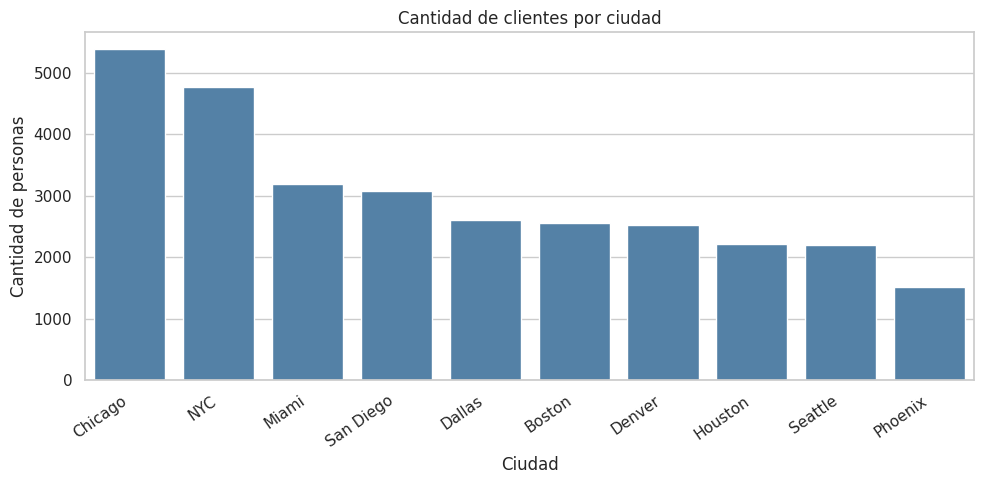

In [16]:
# Preparo una copia de toda la base y aplico reglas de limpieza coherentes con las del análisis de Miami.
df_global_analisis = df_original.copy()
for columna in df_global_analisis.select_dtypes(include='object').columns:
    df_global_analisis[columna] = (
        df_global_analisis[columna].astype('string').str.strip().replace('', pd.NA)
    )
for columna in ['edad', 'frecuencia_visita', 'promedio_gasto_comida', 'ingresos_mensuales']:
    df_global_analisis[columna] = pd.to_numeric(df_global_analisis[columna], errors='coerce')

# Los valores fuera de rango se marcan como faltantes; no elimino a las personas.
df_global_analisis.loc[~df_global_analisis['edad'].between(0, 100), 'edad'] = np.nan
df_global_analisis.loc[df_global_analisis['frecuencia_visita'] < 0, 'frecuencia_visita'] = np.nan
df_global_analisis.loc[df_global_analisis['promedio_gasto_comida'] < 0, 'promedio_gasto_comida'] = np.nan
df_global_analisis.loc[df_global_analisis['ingresos_mensuales'] < 0, 'ingresos_mensuales'] = np.nan

df_global_analisis['gasto_estimado_periodo'] = (
    df_global_analisis['frecuencia_visita'] * df_global_analisis['promedio_gasto_comida']
)

clientes_por_ciudad = (
    df_global_analisis['ciudad_residencia'].value_counts()
    .rename_axis('ciudad').reset_index(name='clientes')
)
clientes_por_ciudad['porcentaje'] = (
    clientes_por_ciudad['clientes'] / len(df_global_analisis) * 100
).round(2)
display(clientes_por_ciudad)

plt.figure(figsize=(10, 5))
sns.barplot(data=clientes_por_ciudad, x='ciudad', y='clientes', color='steelblue')
plt.title('Cantidad de clientes por ciudad')
plt.xlabel('Ciudad')
plt.ylabel('Cantidad de personas')
plt.xticks(rotation=35, ha='right')
plt.tight_layout()
plt.show()

**Interpretación:** Chicago es la ciudad con más registros (5.384), seguida por NYC (4.769). Miami tiene 3.186 clientes, que representan el 10,62% de la base. Esto explica por qué hay una cantidad suficiente de clientes para profundizar el análisis de esa ciudad.

### 13.2. ¿Cómo se distribuyen los estratos socioeconómicos?

Presento cantidad y porcentaje de personas por estrato sobre el total de la base. Así puedo ver si la muestra está concentrada en algún nivel.

,estrato_socioeconomico,clientes,porcentaje
0,Medio,9325,31.08
1,Alto,9038,30.13
2,Bajo,6161,20.54
3,Muy Alto,5476,18.25


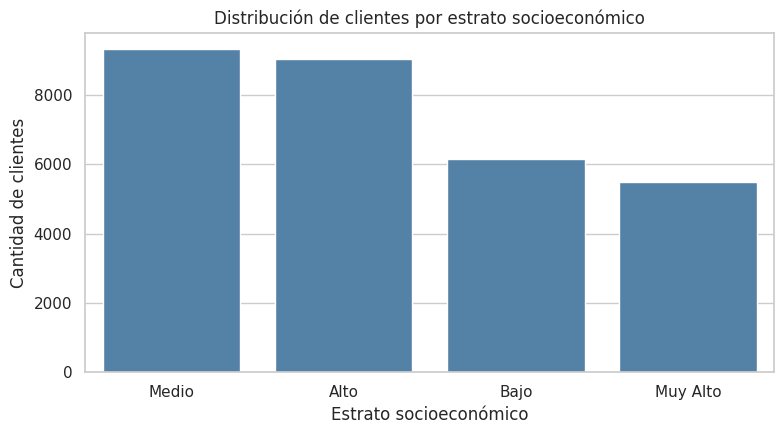

In [17]:
distribucion_estratos = (
    df_global_analisis['estrato_socioeconomico'].value_counts(dropna=False)
    .rename_axis('estrato_socioeconomico').reset_index(name='clientes')
)
distribucion_estratos['porcentaje'] = (
    distribucion_estratos['clientes'] / len(df_global_analisis) * 100
).round(2)
display(distribucion_estratos)

plt.figure(figsize=(8, 4.5))
sns.barplot(data=distribucion_estratos, x='estrato_socioeconomico', y='clientes', color='steelblue')
plt.title('Distribución de clientes por estrato socioeconómico')
plt.xlabel('Estrato socioeconómico')
plt.ylabel('Cantidad de clientes')
plt.tight_layout()
plt.show()

**Interpretación:** el estrato Medio reúne 9.325 personas (31,08%) y el Alto 9.038 (30,13%). En conjunto representan aproximadamente el 61,21% de los registros. El estrato Muy Alto es el menos numeroso, con 5.476 personas (18,25%).

### 13.3. ¿En qué ciudades aparece un mayor gasto estimado?

La consigna menciona gasto mensual en restaurantes, pero la base no especifica si `frecuencia_visita` corresponde a visitas por mes. Para no asumir algo que el archivo no dice, calculo una aproximación por período registrado multiplicando la frecuencia por el gasto promedio por comida. El resultado solo sería mensual si la frecuencia estuviera expresada en visitas mensuales.

,ciudad_residencia,clientes,registros_validos,frecuencia_media,gasto_promedio_comida,gasto_estimado_promedio_periodo
0,Miami,3186,2997,4.78,39.82,225.88
1,San Diego,3075,2897,4.67,34.75,197.80
2,Phoenix,1511,1433,4.18,36.54,197.25
3,Seattle,2191,2069,4.42,36.86,196.14
4,NYC,4769,4492,3.99,37.12,191.38
5,Denver,2523,2395,4.23,34.26,180.86
6,Boston,2547,2418,4.33,29.49,162.75
7,Dallas,2602,2461,4.01,28.70,150.54
8,Chicago,5384,5066,4.21,25.53,139.68
9,Houston,2212,2090,3.95,26.02,128.57


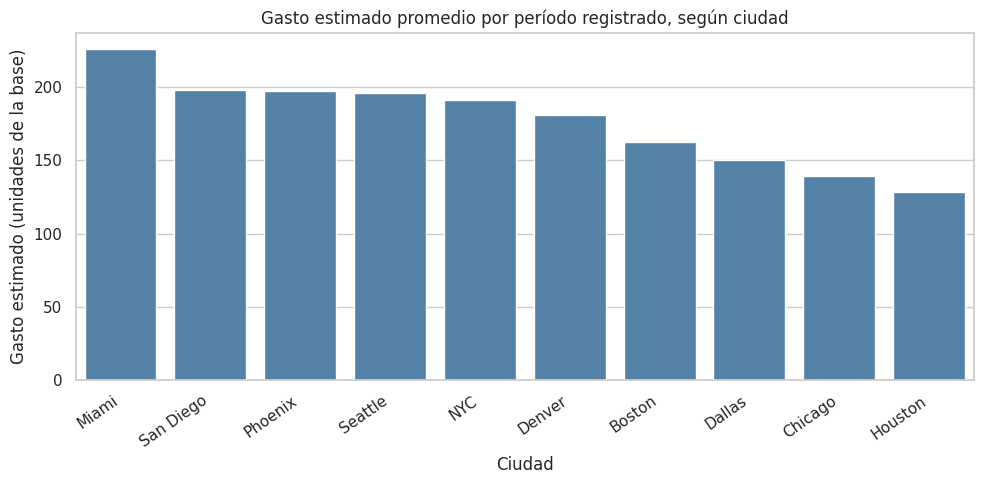

La mayor media estimada aparece en Miami: 225.88 unidades por período registrado, con la salvedad sobre el período de frecuencia.


In [18]:
gasto_por_ciudad = (
    df_global_analisis.groupby('ciudad_residencia')
    .agg(
        clientes=('id_persona', 'size'),
        registros_validos=('gasto_estimado_periodo', 'count'),
        frecuencia_media=('frecuencia_visita', 'mean'),
        gasto_promedio_comida=('promedio_gasto_comida', 'mean'),
        gasto_estimado_promedio_periodo=('gasto_estimado_periodo', 'mean')
    )
    .sort_values('gasto_estimado_promedio_periodo', ascending=False)
    .reset_index()
)
display(gasto_por_ciudad.round(2))

plt.figure(figsize=(10, 5))
sns.barplot(
    data=gasto_por_ciudad,
    x='ciudad_residencia', y='gasto_estimado_promedio_periodo',
    color='steelblue'
)
plt.title('Gasto estimado promedio por período registrado, según ciudad')
plt.xlabel('Ciudad')
plt.ylabel('Gasto estimado (unidades de la base)')
plt.xticks(rotation=35, ha='right')
plt.tight_layout()
plt.show()

ciudad_mayor_gasto_estimado = gasto_por_ciudad.iloc[0]
print(
    f"La mayor media estimada aparece en {ciudad_mayor_gasto_estimado['ciudad_residencia']}: "
    f"{ciudad_mayor_gasto_estimado['gasto_estimado_promedio_periodo']:.2f} unidades "
    "por período registrado, con la salvedad sobre el período de frecuencia."
)

**Interpretación:** Miami presenta la media más alta de esta aproximación (225,88 unidades por período registrado), seguida por San Diego (197,80). No lo llamo gasto mensual confirmado porque la base no define el período de la frecuencia ni la moneda. La comparación es útil como señal exploratoria, siempre que esa limitación quede presente.

### 13.4. ¿Cómo se relacionan frecuencia y gasto promedio por comida según el estrato?

Agrupo por estrato y frecuencia y calculo el gasto promedio por comida. En el gráfico, cada línea representa un estrato. Las frecuencias registradas no aparecen en todos los estratos, por eso comparo los puntos disponibles y no interpreto las líneas como una evolución continua.

,estrato_socioeconomico,frecuencia_visita,clientes,gasto_promedio_comida
0,Alto,4.00,2811,37.94
1,Alto,5.00,2810,38.40
2,Alto,6.00,2893,38.20
3,Bajo,0.00,1463,0.00
4,Bajo,1.00,1453,11.70
5,Bajo,2.00,1452,11.59
6,Bajo,3.00,1468,11.66
7,Medio,2.00,2188,24.31
8,Medio,3.00,2210,23.86
9,Medio,4.00,2209,24.30


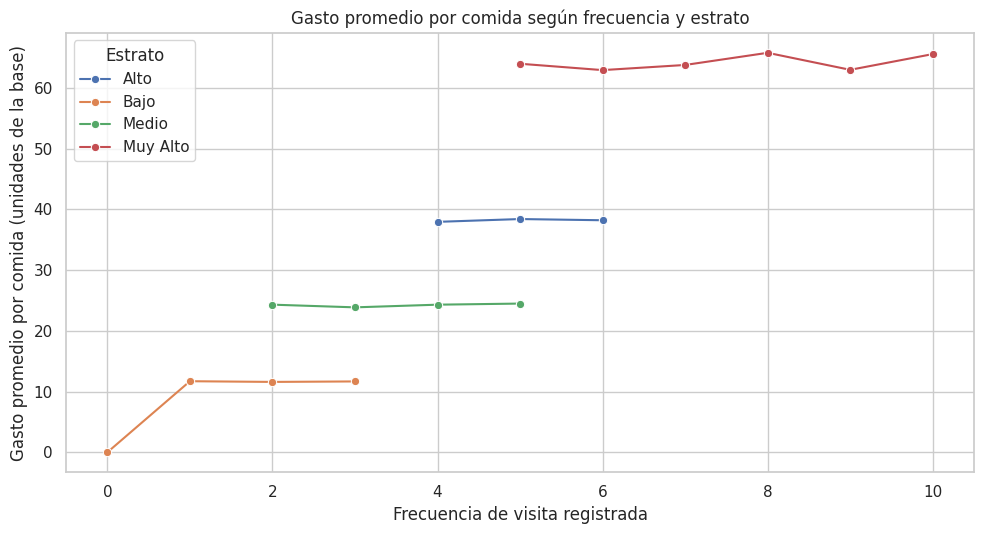

In [19]:
gasto_frecuencia_estrato = (
    df_global_analisis.dropna(subset=['estrato_socioeconomico', 'frecuencia_visita', 'promedio_gasto_comida'])
    .groupby(['estrato_socioeconomico', 'frecuencia_visita'])
    .agg(clientes=('id_persona', 'size'), gasto_promedio_comida=('promedio_gasto_comida', 'mean'))
    .reset_index()
)
display(gasto_frecuencia_estrato.round(2))

plt.figure(figsize=(10, 5.5))
sns.lineplot(
    data=gasto_frecuencia_estrato,
    x='frecuencia_visita', y='gasto_promedio_comida',
    hue='estrato_socioeconomico', marker='o'
)
plt.title('Gasto promedio por comida según frecuencia y estrato')
plt.xlabel('Frecuencia de visita registrada')
plt.ylabel('Gasto promedio por comida (unidades de la base)')
plt.legend(title='Estrato')
plt.tight_layout()
plt.show()

**Interpretación:** se observan diferencias entre estratos. En general, los grupos de estrato más alto registran gastos promedio por comida superiores. También hay que tener en cuenta que los rangos de frecuencia son distintos entre algunos estratos, por lo que el gráfico sirve para describir los datos disponibles, no para afirmar que el estrato por sí solo causa un mayor gasto.

### 13.5. ¿Cómo se relacionan los ingresos mensuales con el gasto estimado?

Uso un gráfico de dispersión entre los ingresos mensuales informados y el gasto estimado por período registrado. Como se explicó antes, no puedo llamarlo gasto mensual confirmado sin conocer el período de la frecuencia.

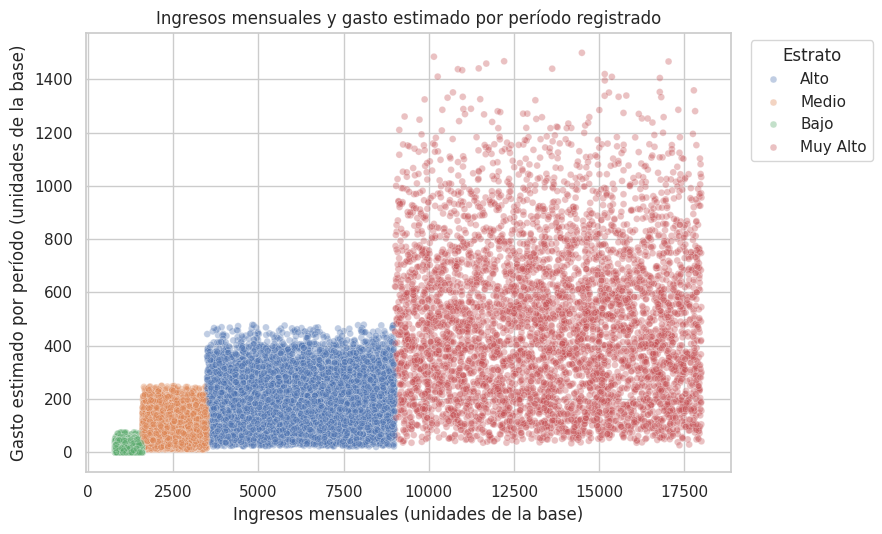

Correlación de Pearson entre ingresos y gasto estimado: 0.71


In [20]:
datos_ingreso_gasto = df_global_analisis.dropna(subset=['ingresos_mensuales', 'gasto_estimado_periodo'])
correlacion_ingreso_gasto = datos_ingreso_gasto['ingresos_mensuales'].corr(
    datos_ingreso_gasto['gasto_estimado_periodo']
)

plt.figure(figsize=(9, 5.5))
sns.scatterplot(
    data=datos_ingreso_gasto,
    x='ingresos_mensuales', y='gasto_estimado_periodo',
    hue='estrato_socioeconomico', alpha=0.35, s=24
)
plt.title('Ingresos mensuales y gasto estimado por período registrado')
plt.xlabel('Ingresos mensuales (unidades de la base)')
plt.ylabel('Gasto estimado por período (unidades de la base)')
plt.legend(title='Estrato', bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout()
plt.show()
print(f'Correlación de Pearson entre ingresos y gasto estimado: {correlacion_ingreso_gasto:.2f}')

**Interpretación:** la correlación observada es positiva (aproximadamente 0,71): en esta base, los ingresos más altos tienden a aparecer junto con valores más altos de gasto estimado. La correlación no demuestra causalidad y el gasto calculado sigue dependiendo de la limitación sobre el período de frecuencia.

### 13.6. ¿Cómo cambian las preferencias alimenticias entre ciudades?

Calculo la distribución porcentual de cada preferencia dentro de cada ciudad. Excluyo los valores sin informar del denominador de las preferencias válidas y muestro su cantidad por separado.

Cantidad de respuestas por preferencia y ciudad:


preferencias_alimenticias,Carnes,Mariscos,Otro,Pescado,Vegano,Vegetariano
ciudad_residencia,,,,,,
Boston,535,493,198,272,239,708
Chicago,1589,696,591,546,571,1123
Dallas,822,366,249,239,258,539
Denver,632,468,172,249,258,626
Houston,716,333,238,229,197,411
Miami,511,819,293,307,382,728
NYC,1513,799,396,436,588,837
Phoenix,416,209,154,200,155,301
San Diego,656,584,194,288,407,756


Porcentaje dentro de las respuestas registradas en cada ciudad:


preferencias_alimenticias,Carnes,Mariscos,Otro,Pescado,Vegano,Vegetariano
ciudad_residencia,,,,,,
Boston,21.90,20.20,8.10,11.10,9.80,29.00
Chicago,31.10,13.60,11.60,10.70,11.20,22.00
Dallas,33.20,14.80,10.10,9.70,10.40,21.80
Denver,26.30,19.50,7.20,10.40,10.70,26.00
Houston,33.70,15.70,11.20,10.80,9.30,19.40
Miami,16.80,26.90,9.60,10.10,12.60,23.90
NYC,33.10,17.50,8.70,9.50,12.90,18.30
Phoenix,29.00,14.60,10.70,13.90,10.80,21.00
San Diego,22.70,20.20,6.70,10.00,14.10,26.20


Preferencias sin informar por ciudad:


,sin_informar
ciudad_residencia,
Boston,102
Chicago,268
Dallas,129
Denver,118
Houston,88
Miami,146
NYC,200
Phoenix,76
San Diego,190


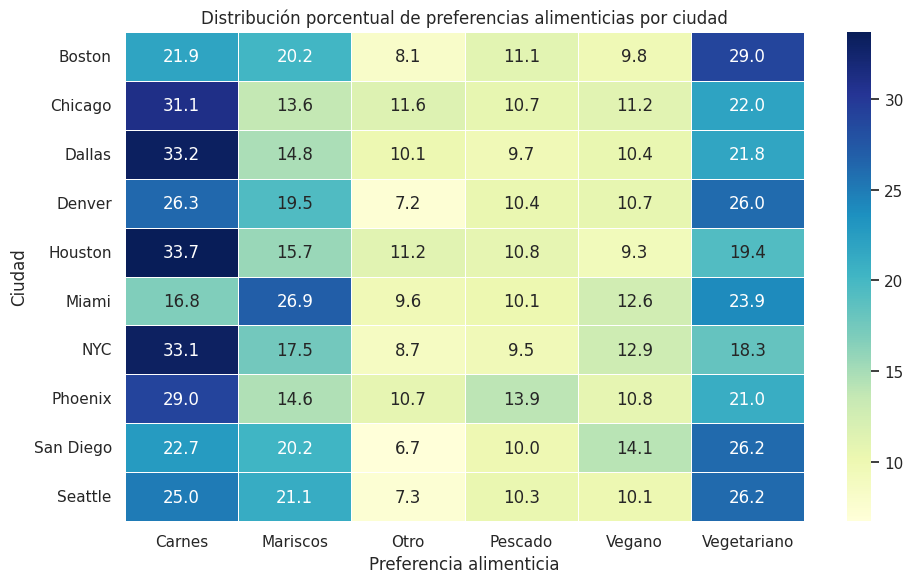

In [21]:
preferencias_por_ciudad = pd.crosstab(
    df_global_analisis['ciudad_residencia'],
    df_global_analisis['preferencias_alimenticias']
)
preferencias_por_ciudad_pct = pd.crosstab(
    df_global_analisis['ciudad_residencia'],
    df_global_analisis['preferencias_alimenticias'],
    normalize='index'
) * 100

print('Cantidad de respuestas por preferencia y ciudad:')
display(preferencias_por_ciudad)
print('Porcentaje dentro de las respuestas registradas en cada ciudad:')
display(preferencias_por_ciudad_pct.round(1))
print('Preferencias sin informar por ciudad:')
display(df_global_analisis.groupby('ciudad_residencia')['preferencias_alimenticias'].apply(lambda s: s.isna().sum()).to_frame('sin_informar'))

plt.figure(figsize=(10, 6))
sns.heatmap(preferencias_por_ciudad_pct, annot=True, fmt='.1f', cmap='YlGnBu', linewidths=.4)
plt.title('Distribución porcentual de preferencias alimenticias por ciudad')
plt.xlabel('Preferencia alimenticia')
plt.ylabel('Ciudad')
plt.tight_layout()
plt.show()

**Interpretación:** las preferencias cambian según la ciudad. Miami presenta una proporción relativamente alta de Mariscos (26,94%), mientras que Carnes tiene mayor presencia en ciudades como Houston, Dallas y NYC. Las opciones vegetarianas también aparecen con porcentajes relevantes, por ejemplo en Boston, San Diego y Seattle. Esto sugiere que las campañas pueden adaptar los mensajes a cada mercado en lugar de utilizar la misma comunicación en todas las ciudades.

### 13.7. ¿Cómo son los clientes del grupo de mayor gasto?

Para definir este perfil tomo el 25% de clientes con mayor gasto estimado por período registrado, calculado como frecuencia por gasto promedio por comida. La definición es relativa a la base y no representa un nivel absoluto de gasto. Excluyo los registros que no tienen alguno de esos dos datos.

,indicador,valor
0,Clientes dentro del perfil,"7,080.00"
1,Umbral del 25% superior,227.63
2,Frecuencia media registrada,6.63
3,Gasto promedio por comida,68.42
4,Gasto estimado promedio por período,459.99
5,Ingresos mensuales promedio,"10,332.58"
6,Edad promedio,48.67


,preferencia,clientes,porcentaje
0,Carnes,1800,25.42
1,Vegetariano,1648,23.28
2,Mariscos,1271,17.95
3,Vegano,767,10.83
4,Pescado,673,9.51
5,Otro,583,8.23
6,Sin informar,338,4.77


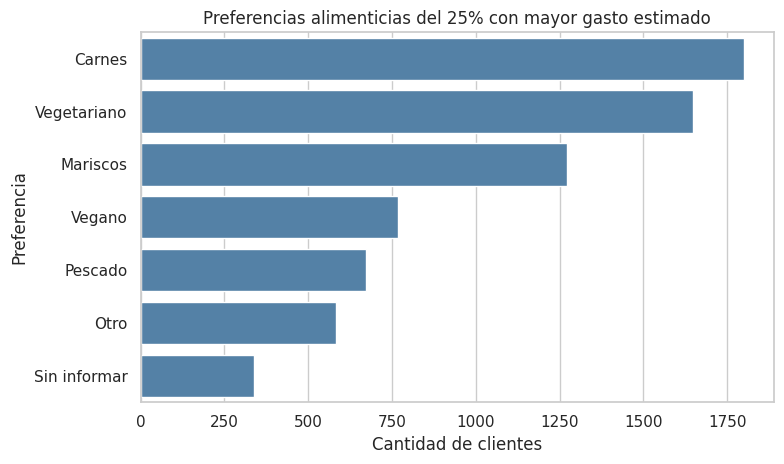

In [22]:
clientes_con_gasto_estimado = df_global_analisis.dropna(subset=['gasto_estimado_periodo']).copy()
umbral_mayor_gasto = clientes_con_gasto_estimado['gasto_estimado_periodo'].quantile(0.75)
clientes_mayor_gasto = clientes_con_gasto_estimado[
    clientes_con_gasto_estimado['gasto_estimado_periodo'] >= umbral_mayor_gasto
].copy()

resumen_mayor_gasto = pd.DataFrame({
    'indicador': [
        'Clientes dentro del perfil', 'Umbral del 25% superior',
        'Frecuencia media registrada', 'Gasto promedio por comida',
        'Gasto estimado promedio por período', 'Ingresos mensuales promedio', 'Edad promedio'
    ],
    'valor': [
        len(clientes_mayor_gasto), umbral_mayor_gasto,
        clientes_mayor_gasto['frecuencia_visita'].mean(),
        clientes_mayor_gasto['promedio_gasto_comida'].mean(),
        clientes_mayor_gasto['gasto_estimado_periodo'].mean(),
        clientes_mayor_gasto['ingresos_mensuales'].mean(),
        clientes_mayor_gasto['edad'].mean()
    ]
})
display(resumen_mayor_gasto.round(2))

preferencias_mayor_gasto = (
    clientes_mayor_gasto['preferencias_alimenticias'].fillna('Sin informar')
    .value_counts().rename_axis('preferencia').reset_index(name='clientes')
)
preferencias_mayor_gasto['porcentaje'] = (
    preferencias_mayor_gasto['clientes'] / len(clientes_mayor_gasto) * 100
).round(2)
display(preferencias_mayor_gasto)

plt.figure(figsize=(8, 4.8))
sns.barplot(data=preferencias_mayor_gasto, x='clientes', y='preferencia', color='steelblue')
plt.title('Preferencias alimenticias del 25% con mayor gasto estimado')
plt.xlabel('Cantidad de clientes')
plt.ylabel('Preferencia')
plt.tight_layout()
plt.show()

**Interpretación:** el perfil del 25% superior reúne 7.080 personas entre los 28.318 registros con gasto estimado válido. Sus preferencias más frecuentes son Carnes (1.800 personas), Vegetariano (1.648) y Mariscos (1.271). El gasto promedio por comida de este grupo es de 68,42 unidades de la base y su frecuencia media registrada es 6,63. El gasto estimado por período promedia 459,99 unidades, pero no se puede llamar mensual hasta confirmar el período de la frecuencia.

### 13.8. ¿En qué ciudad hay más membresías premium?

Comparo tanto la cantidad de membresías como el porcentaje de clientes con membresía en cada ciudad. La cantidad responde dónde hay más personas afiliadas; el porcentaje permite comparar ciudades de distinto tamaño.

,ciudad_residencia,clientes,membresias_premium,porcentaje_con_membresia
0,Chicago,5384,2215,41.14
1,NYC,4769,1775,37.22
2,Miami,3186,1694,53.17
3,San Diego,3075,1502,48.85
4,Boston,2547,1139,44.72
5,Denver,2523,1068,42.33
6,Seattle,2191,1023,46.69
7,Dallas,2602,992,38.12
8,Houston,2212,808,36.53
9,Phoenix,1511,629,41.63


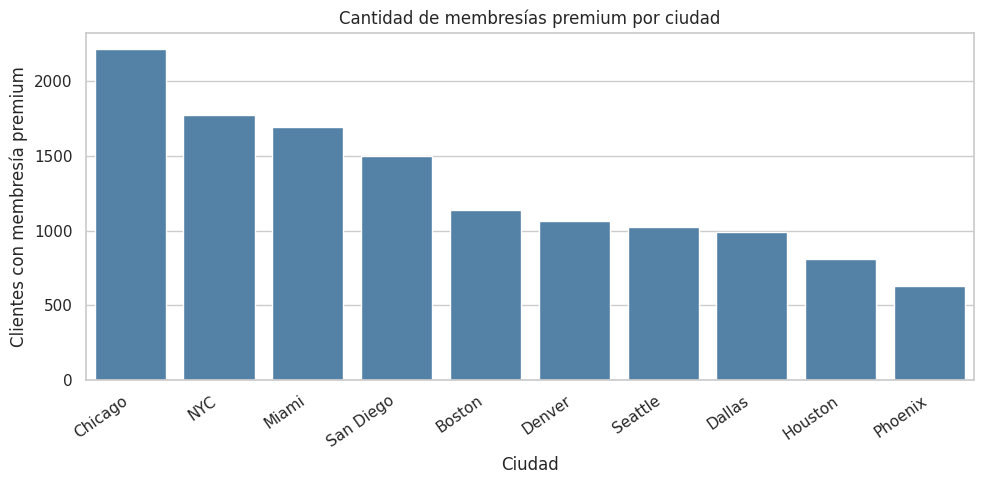

Mayor cantidad: Chicago - 2215 membresías
Mayor proporción: Miami - 53.17 %


In [23]:
resumen_membresias_ciudad = (
    df_global_analisis.assign(tiene_membresia=df_global_analisis['membresia_premium'].eq('Sí'))
    .groupby('ciudad_residencia')
    .agg(clientes=('id_persona', 'size'), membresias_premium=('tiene_membresia', 'sum'),
         porcentaje_con_membresia=('tiene_membresia', 'mean'))
    .sort_values('membresias_premium', ascending=False)
    .reset_index()
)
resumen_membresias_ciudad['porcentaje_con_membresia'] = (
    resumen_membresias_ciudad['porcentaje_con_membresia'] * 100
).round(2)
display(resumen_membresias_ciudad)

plt.figure(figsize=(10, 5))
sns.barplot(data=resumen_membresias_ciudad, x='ciudad_residencia', y='membresias_premium', color='steelblue')
plt.title('Cantidad de membresías premium por ciudad')
plt.xlabel('Ciudad')
plt.ylabel('Clientes con membresía premium')
plt.xticks(rotation=35, ha='right')
plt.tight_layout()
plt.show()

print('Mayor cantidad:', resumen_membresias_ciudad.iloc[0]['ciudad_residencia'],
      '-', int(resumen_membresias_ciudad.iloc[0]['membresias_premium']), 'membresías')
print('Mayor proporción:', resumen_membresias_ciudad.sort_values('porcentaje_con_membresia', ascending=False).iloc[0]['ciudad_residencia'],
      '-', resumen_membresias_ciudad['porcentaje_con_membresia'].max(), '%')

**Interpretación:** Chicago es la ciudad con mayor cantidad absoluta de membresías premium (2.215). Sin embargo, Miami tiene la mayor proporción de clientes con membresía (53,17%). Son dos lecturas distintas: Chicago concentra más afiliados porque tiene más clientes en la base, mientras que en Miami la penetración de la membresía es mayor.

### 13.9. ¿Qué relación hay entre edad y consumo de alcohol?

Comparo las edades de quienes indican que consumen licor en restaurantes con quienes indican que no. Presento un resumen de edad y un diagrama de caja para ver la distribución de ambos grupos.

,consume_licor,clientes_con_edad,edad_promedio,edad_mediana,edad_minima,edad_maxima
0,No,11363,53.64,52.00,18.00,80.00
1,Sí,18329,45.99,46.00,18.00,80.00


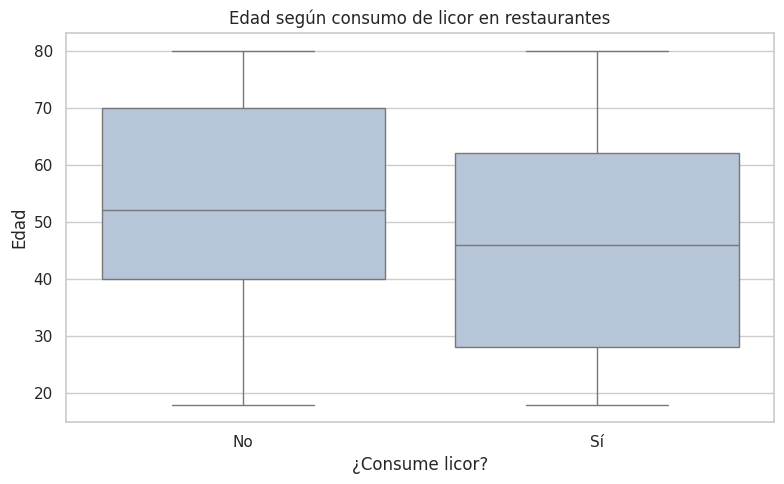

In [24]:
edad_consumo_alcohol = (
    df_global_analisis.dropna(subset=['edad'])
    .groupby('consume_licor')
    .agg(clientes_con_edad=('id_persona', 'size'), edad_promedio=('edad', 'mean'),
         edad_mediana=('edad', 'median'), edad_minima=('edad', 'min'), edad_maxima=('edad', 'max'))
    .reset_index()
)
display(edad_consumo_alcohol.round(2))

plt.figure(figsize=(8, 5))
sns.boxplot(data=df_global_analisis.dropna(subset=['edad']), x='consume_licor', y='edad', color='lightsteelblue')
plt.title('Edad según consumo de licor en restaurantes')
plt.xlabel('¿Consume licor?')
plt.ylabel('Edad')
plt.tight_layout()
plt.show()

**Interpretación:** entre las personas con edad informada, quienes declaran consumir licor tienen una edad promedio de 45,99 años (mediana 46), mientras que quienes indican que no consumen tienen una media de 53,64 años (mediana 52). La diferencia describe esta base, pero no permite afirmar que la edad sea la causa del consumo.

### 13.10. Resumen de los hallazgos generales

Con esta parte respondo las preguntas generales del Avance 3 usando las diez ciudades. Para el análisis más específico de segmentación y contexto gastronómico sigo trabajando con Miami y con los datos de Yelp obtenidos en el Avance 2.

In [25]:
print(f"La base tiene {len(df_global_analisis):,} clientes distribuidos en {df_global_analisis['ciudad_residencia'].nunique()} ciudades.")
print(f"La ciudad con más clientes es {clientes_por_ciudad.iloc[0]['ciudad']} ({int(clientes_por_ciudad.iloc[0]['clientes']):,}).")
print(f"La ciudad con mayor gasto estimado por período es {gasto_por_ciudad.iloc[0]['ciudad_residencia']} ({gasto_por_ciudad.iloc[0]['gasto_estimado_promedio_periodo']:.2f} unidades).")
print(f"La ciudad con más membresías es {resumen_membresias_ciudad.iloc[0]['ciudad_residencia']} ({int(resumen_membresias_ciudad.iloc[0]['membresias_premium']):,}); la mayor proporción es de {resumen_membresias_ciudad.sort_values('porcentaje_con_membresia', ascending=False).iloc[0]['ciudad_residencia']}.")
print(f"El perfil del 25% superior contiene {len(clientes_mayor_gasto):,} clientes y tiene un gasto promedio por comida de {clientes_mayor_gasto['promedio_gasto_comida'].mean():.2f} unidades.")

La base tiene 30,000 clientes distribuidos en 10 ciudades.
La ciudad con más clientes es Chicago (5,384).
La ciudad con mayor gasto estimado por período es Miami (225.88 unidades).
La ciudad con más membresías es Chicago (2,215); la mayor proporción es de Miami.
El perfil del 25% superior contiene 7,080 clientes y tiene un gasto promedio por comida de 68.42 unidades.


## 14. ¿Qué grupos aparecen?

Al cruzar las dos variables quedan cuatro grupos. Cuando digo "mayor gasto", me refiero a estar por encima de la mediana de esta base; no significa necesariamente que sea un gasto alto para cualquier negocio.

,clientes,frecuencia_media,gasto_medio,ingreso_medio,porcentaje_premium,edad_media,porcentaje_clientes
segmento,,,,,,,
Frecuentes y de mayor gasto,1128,6.51,65.69,"10,000.34",81.83,48.81,37.64
Frecuentes y de menor gasto,550,5.99,21.35,"7,411.44",62.55,49.55,18.35
Menos frecuentes y de mayor gasto,371,3.64,44.85,"4,807.70",50.13,49.90,12.38
Menos frecuentes y de menor gasto,948,2.48,17.34,"2,401.82",15.08,49.13,31.63


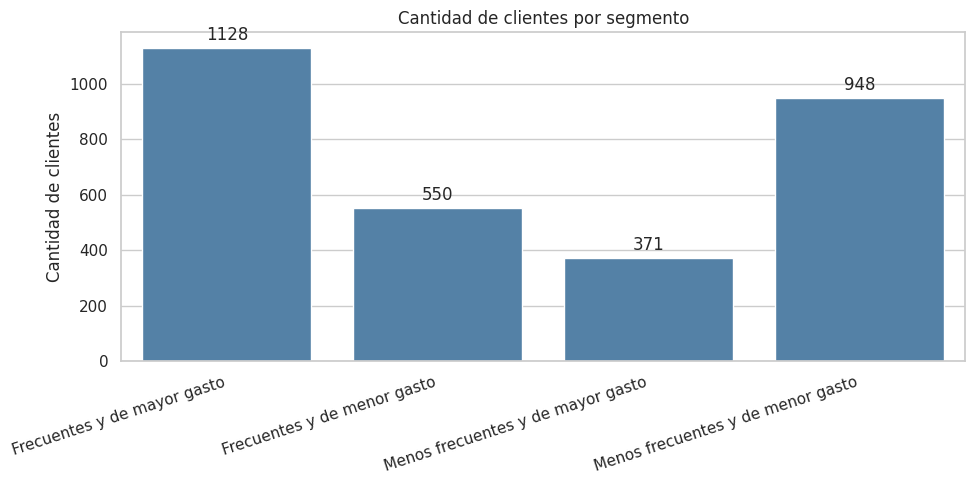

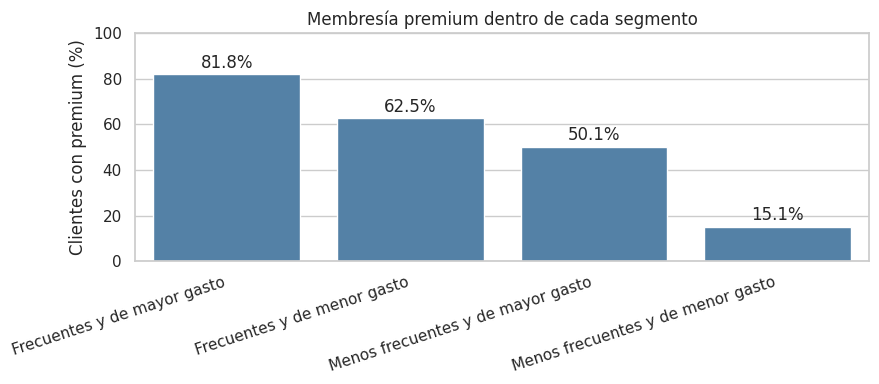

In [26]:
tabla_segmentos = (
    df_segmentacion.groupby("segmento", observed=False)
    .agg(
        clientes=("id_persona", "count"),
        frecuencia_media=("frecuencia_visita", "mean"),
        gasto_medio=("promedio_gasto_comida", "mean"),
        ingreso_medio=("ingresos_mensuales", "mean"),
        porcentaje_premium=("membresia_premium", lambda s: (s == "Sí").mean() * 100),
        edad_media=("edad", "mean")
    )
)

tabla_segmentos["porcentaje_clientes"] = tabla_segmentos["clientes"] / len(df_segmentacion) * 100
orden_segmentos = [
    "Frecuentes y de mayor gasto",
    "Frecuentes y de menor gasto",
    "Menos frecuentes y de mayor gasto",
    "Menos frecuentes y de menor gasto"
]
tabla_segmentos = tabla_segmentos.reindex(orden_segmentos).round(2)
display(tabla_segmentos)

plt.figure(figsize=(10, 5))
ax = sns.barplot(
    data=tabla_segmentos.reset_index(),
    x="segmento", y="clientes", color="steelblue"
)
plt.title("Cantidad de clientes por segmento")
plt.xlabel("")
plt.ylabel("Cantidad de clientes")
plt.xticks(rotation=18, ha="right")
for contenedor in ax.containers:
    ax.bar_label(contenedor, fmt="%d", padding=3)
plt.tight_layout()
plt.show()

# También miro qué porcentaje de cada grupo tiene membresía premium.
plt.figure(figsize=(9, 4))
plot_premium_segmentos = tabla_segmentos.reset_index()
ax = sns.barplot(
    data=plot_premium_segmentos,
    x="segmento", y="porcentaje_premium", color="steelblue"
)
plt.title("Membresía premium dentro de cada segmento")
plt.xlabel("")
plt.ylabel("Clientes con premium (%)")
plt.xticks(rotation=18, ha="right")
plt.ylim(0, 100)
for contenedor in ax.containers:
    ax.bar_label(contenedor, fmt="%.1f%%", padding=2)
plt.tight_layout()
plt.show()

### Qué muestran los grupos

El grupo más grande es el de clientes con menor frecuencia y menor gasto (31,63%). También hay un grupo importante de clientes frecuentes y de mayor gasto (37,64%). Me parece que conviene pensar propuestas distintas para estos dos perfiles.

La clasificación es una forma sencilla de ordenar los datos. No quiere decir que todas las personas de un grupo se comporten exactamente igual.

## 15. Relación entre frecuencia y gasto

En el gráfico se ven los clientes que tienen ambos datos. Las líneas marcan las medianas que usé para separarlos en grupos.

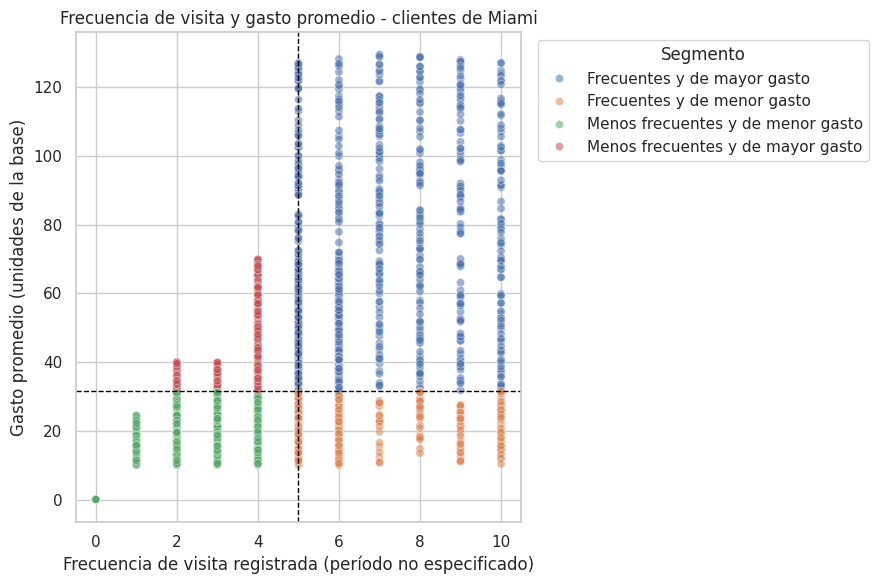

Correlación entre frecuencia y gasto: 0.56


In [27]:
plt.figure(figsize=(9, 6))
sns.scatterplot(
    data=df_segmentacion,
    x="frecuencia_visita",
    y="promedio_gasto_comida",
    hue="segmento",
    alpha=0.55,
    s=35
)
plt.axvline(mediana_frecuencia, color="black", linestyle="--", linewidth=1)
plt.axhline(mediana_gasto, color="black", linestyle="--", linewidth=1)
plt.title("Frecuencia de visita y gasto promedio - clientes de Miami")
plt.xlabel("Frecuencia de visita registrada (período no especificado)")
plt.ylabel("Gasto promedio (unidades de la base)")
plt.legend(title="Segmento", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

correlacion_frecuencia_gasto = df_segmentacion[[
    "frecuencia_visita", "promedio_gasto_comida"
]].corr().iloc[0, 1]
print(f"Correlación entre frecuencia y gasto: {correlacion_frecuencia_gasto:.2f}")

La relación entre frecuencia y gasto es positiva: en general, quienes registran más visitas también tienen un gasto medio más alto. De todos modos, hay clientes que visitan menos y gastan más en cada visita. Para ese grupo podría probarse una campaña para recordarles el negocio o mostrarles alguna novedad.

## 16. Membresía premium por estrato

Comparo qué porcentaje de cada estrato tiene membresía premium. Esto permite ver si hay diferencias entre los grupos, aunque no explica por qué cada persona eligió contratarla o no.

,clientes,gasto_medio,frecuencia_media,ingreso_medio,premium_pct
estrato_socioeconomico,,,,,
Alto,1159,40.10,5.00,"6,198.78",70.32
Muy Alto,799,68.77,7.51,"13,660.96",95.62
Medio,783,24.89,3.51,"2,557.81",14.56
Bajo,445,13.34,1.53,"1,193.47",0.22


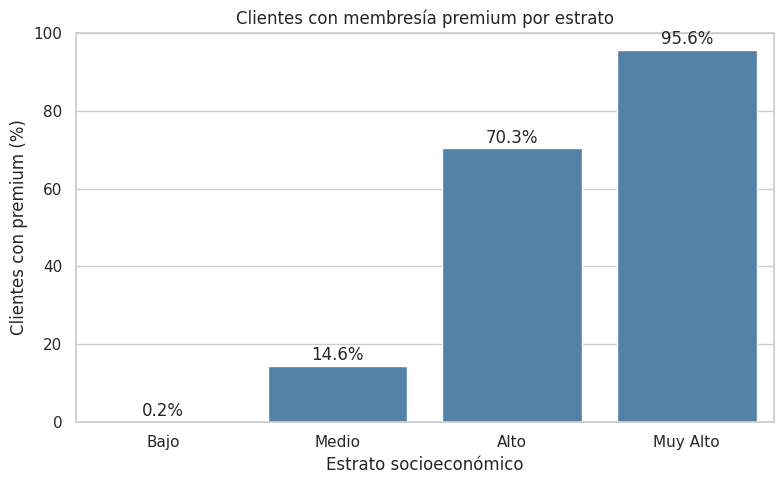

In [28]:
tabla_estratos_avance3 = (
    df_limpio.groupby("estrato_socioeconomico", dropna=False)
    .agg(
        clientes=("id_persona", "count"),
        gasto_medio=("promedio_gasto_comida", "mean"),
        frecuencia_media=("frecuencia_visita", "mean"),
        ingreso_medio=("ingresos_mensuales", "mean"),
        premium_pct=("membresia_premium", lambda s: (s == "Sí").mean() * 100)
    )
    .sort_values("clientes", ascending=False)
    .round(2)
)
display(tabla_estratos_avance3)

plt.figure(figsize=(8, 5))
orden = [x for x in ["Bajo", "Medio", "Alto", "Muy Alto"] if x in df_limpio["estrato_socioeconomico"].dropna().unique()]
porcentaje_premium = (
    df_limpio.assign(es_premium=df_limpio["membresia_premium"].eq("Sí"))
    .groupby("estrato_socioeconomico")["es_premium"].mean().reindex(orden) * 100
)
sns.barplot(x=porcentaje_premium.index, y=porcentaje_premium.values, color="steelblue")
plt.title("Clientes con membresía premium por estrato")
plt.xlabel("Estrato socioeconómico")
plt.ylabel("Clientes con premium (%)")
plt.ylim(0, 100)
for i, valor in enumerate(porcentaje_premium.values):
    plt.text(i, valor + 1.5, f"{valor:.1f}%", ha="center")
plt.tight_layout()
plt.show()

La membresía premium aparece bastante más en los estratos Alto y Muy Alto que en el Bajo y el Medio. Una posibilidad sería probar una opción más accesible para el estrato Medio, pero antes habría que averiguar si el precio es realmente el motivo por el que hay menos membresías.

## 17. Comparo las preferencias de clientes con las categorías de Yelp

Primero miro las preferencias alimenticias declaradas por los clientes de Miami. Después las comparo con las categorías de los 100 negocios recibidos de Yelp y, como referencia geográfica adicional, con los 83 negocios cuya ciudad informada es exactamente Miami.

Los porcentajes tienen denominadores diferentes: el porcentaje de clientes se calcula sobre las respuestas válidas de clientes; el porcentaje de Yelp, sobre la cantidad de negocios de cada muestra. La comparación es orientativa y no implica que cada restaurante tenga todos los platos asociados a una categoría.

,clientes,porcentaje_respuestas_validas
preferencias_alimenticias,,
Mariscos,819,26.94
Vegetariano,728,23.95
Carnes,511,16.81
Vegano,382,12.57
Pescado,307,10.10
Otro,293,9.64


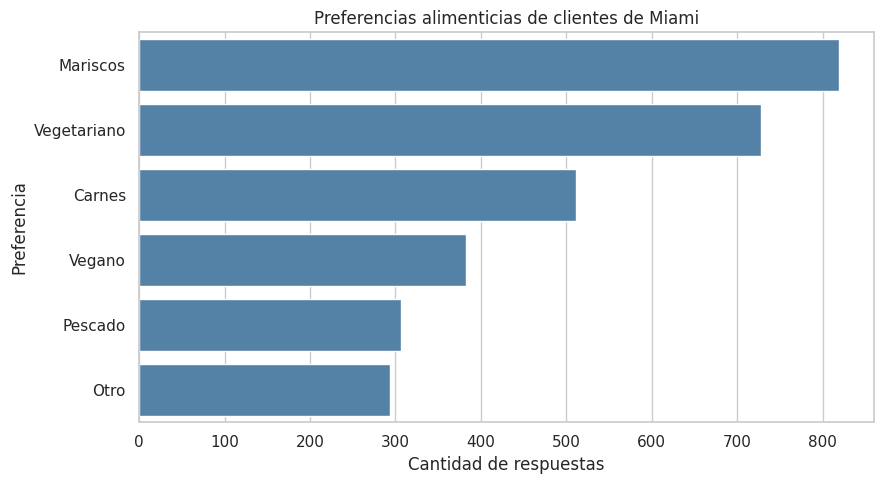

Negocios de la búsqueda completa: 100
Negocios cuya ciudad informada es Miami: 83
Negocios de localidades cercanas: 17
Categorías más frecuentes en los 100 negocios:


,negocios
title,
Italian,11
New American,10
Steakhouses,9
Cocktail Bars,9
Asian Fusion,8
Mediterranean,8
Seafood,8
Mexican,7
Cuban,6


Categorías más frecuentes en los 83 negocios con ciudad Miami:


,negocios
title,
Italian,8
Steakhouses,8
Cocktail Bars,7
Mexican,7
New American,7
Asian Fusion,7
Cuban,6
Mediterranean,6
Seafood,6


In [29]:
# Preferencias de clientes: calculo porcentajes sobre respuestas no vacías.
preferencias_clientes = df_limpio["preferencias_alimenticias"].dropna().value_counts()
tabla_preferencias_avance3 = preferencias_clientes.rename("clientes").to_frame()
tabla_preferencias_avance3["porcentaje_respuestas_validas"] = (
    preferencias_clientes / preferencias_clientes.sum() * 100
).round(2)
display(tabla_preferencias_avance3)

plt.figure(figsize=(9, 5))
sns.barplot(
    x=tabla_preferencias_avance3["clientes"].values,
    y=tabla_preferencias_avance3.index,
    color="steelblue"
)
plt.title("Preferencias alimenticias de clientes de Miami")
plt.xlabel("Cantidad de respuestas")
plt.ylabel("Preferencia")
plt.tight_layout()
plt.show()

# Mantengo los 100 resultados para el análisis de la búsqueda completa.
df_yelp_busqueda = df_yelp_original.drop_duplicates(subset="id").copy()
ids_busqueda = set(df_yelp_busqueda["id"])
df_yelp_categorias_busqueda = df_yelp_categorias_original[
    df_yelp_categorias_original["id"].isin(ids_busqueda)
].drop_duplicates(subset=["id", "alias"]).copy()

# Además separo los negocios con ciudad exacta Miami para la comparación local.
df_yelp_trabajo = df_yelp_busqueda[
    df_yelp_busqueda["city"].astype("string").str.strip().str.casefold() == CIUDAD_OBJETIVO.casefold()
].copy()
ids_yelp_miami = set(df_yelp_trabajo["id"])
df_yelp_categorias_trabajo = df_yelp_categorias_busqueda[
    df_yelp_categorias_busqueda["id"].isin(ids_yelp_miami)
].copy()

categorias_yelp_busqueda = (
    df_yelp_categorias_busqueda.groupby("title")["id"].nunique()
    .sort_values(ascending=False).rename("negocios").to_frame()
)
categorias_yelp = (
    df_yelp_categorias_trabajo.groupby("title")["id"].nunique()
    .sort_values(ascending=False).rename("negocios").to_frame()
)

print("Negocios de la búsqueda completa:", df_yelp_busqueda["id"].nunique())
print("Negocios cuya ciudad informada es Miami:", df_yelp_trabajo["id"].nunique())
print("Negocios de localidades cercanas:", len(df_yelp_busqueda) - len(df_yelp_trabajo))
print("Categorías más frecuentes en los 100 negocios:")
display(categorias_yelp_busqueda.head(15))
print("Categorías más frecuentes en los 83 negocios con ciudad Miami:")
display(categorias_yelp.head(15))

En las respuestas válidas de los clientes, las preferencias más frecuentes son **Mariscos (26,94%)**, **Vegetariano (23,95%)** y **Vegano (12,57%)**.

En la muestra completa de 100 negocios, 8 tienen la categoría Seafood y 1 tiene la etiqueta Vegan; no aparece la etiqueta Vegetarian. Al mirar solo los 83 negocios cuya ciudad informada es Miami, 6 tienen la categoría Seafood y no aparecen las etiquetas Vegetarian ni Vegan.

Esto no demuestra que falten platos vegetarianos o veganos: las categorías de Yelp son etiquetas del negocio y no describen necesariamente todo el menú. La comparación sirve para orientar qué información convendría revisar en los menús antes de diseñar campañas.

In [30]:
# Comparo preferencias de clientes con etiquetas presentes en Yelp.
# Las columnas de 100 negocios representan toda la búsqueda; las de 83, la ciudad exacta Miami.
mapa_preferencias_yelp = {
    "Mariscos": "Seafood",
    "Vegetariano": "Vegetarian",
    "Vegano": "Vegan"
}

filas_comparacion = []
total_preferencias_validas = preferencias_clientes.sum()
total_negocios_busqueda = df_yelp_busqueda["id"].nunique()
total_negocios_miami = df_yelp_trabajo["id"].nunique()

for preferencia, categoria in mapa_preferencias_yelp.items():
    cantidad_clientes = int(preferencias_clientes.get(preferencia, 0))
    cantidad_negocios_busqueda = int(categorias_yelp_busqueda["negocios"].get(categoria, 0))
    cantidad_negocios_miami = int(categorias_yelp["negocios"].get(categoria, 0))
    filas_comparacion.append({
        "preferencia_clientes": preferencia,
        "clientes": cantidad_clientes,
        "porcentaje_clientes_con_preferencia": round(cantidad_clientes / total_preferencias_validas * 100, 2),
        "categoria_yelp_relacionada": categoria,
        "negocios_en_100_resultados": cantidad_negocios_busqueda,
        "porcentaje_sobre_100_resultados": round(cantidad_negocios_busqueda / total_negocios_busqueda * 100, 2),
        "negocios_en_83_de_miami": cantidad_negocios_miami,
        "porcentaje_sobre_83_de_miami": round(cantidad_negocios_miami / total_negocios_miami * 100, 2)
    })

tabla_comparacion_preferencias = pd.DataFrame(filas_comparacion)
display(tabla_comparacion_preferencias)

,preferencia_clientes,clientes,porcentaje_clientes_con_preferencia,categoria_yelp_relacionada,negocios_en_100_resultados,porcentaje_sobre_100_resultados,negocios_en_83_de_miami,porcentaje_sobre_83_de_miami
0,Mariscos,819,26.94,Seafood,8,8.00,6,7.23
1,Vegetariano,728,23.95,Vegetarian,0,0.00,0,0.00
2,Vegano,382,12.57,Vegan,1,1.00,0,0.00


## 18. Calificaciones, reseñas y precios

Primero resumo los 100 negocios de la búsqueda completa. Después muestro los mismos indicadores para los 83 negocios cuya ciudad informada es Miami. Las reseñas reflejan actividad dentro de Yelp, pero no equivalen a ventas ni a la cantidad total de clientes de un restaurante.

Resumen de los 100 negocios de la búsqueda:


,count,mean,std,min,25%,50%,75%,max
rating,100.00,4.38,0.32,3.60,4.10,4.40,4.60,5.00
review_count,100.00,686.80,"1,107.22",4.00,93.75,269.50,792.50,"7,100.00"
distance_km,100.00,5.79,2.94,0.77,3.20,5.27,7.48,12.80


Nivel de precio informado en los 100 negocios:


,negocios
price,
Medio,41
No especificado,39
Alto,16
Bajo,3
Muy Alto,1


Resumen de los 83 negocios cuya ciudad informada es Miami:


,count,mean,std,min,25%,50%,75%,max
rating,83.00,4.39,0.31,3.60,4.20,4.40,4.60,5.00
review_count,83.00,720.30,"1,183.50",4.00,91.50,284.00,779.00,"7,100.00"
distance_km,83.00,6.07,2.96,0.77,3.75,5.34,8.37,12.80


Nivel de precio informado en los 83 negocios de Miami:


,negocios
price,
Medio,35
No especificado,32
Alto,12
Bajo,3
Muy Alto,1


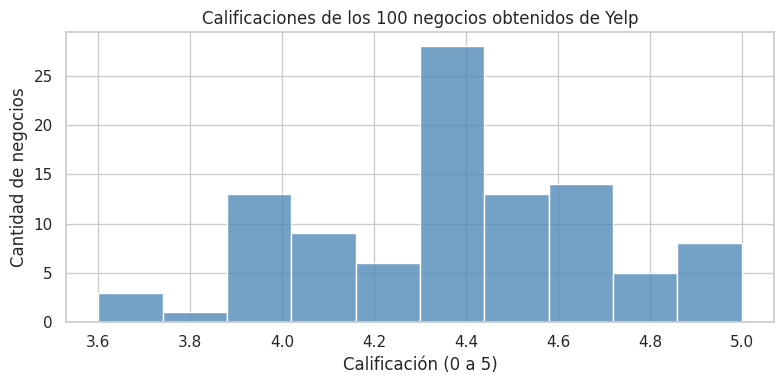

Diez negocios con más reseñas dentro de los 100 resultados:


,name,city,rating,review_count,price
0,Versailles,Miami,4.00,7100,Medio
1,CVI.CHE 105,Miami,4.40,6222,Alto
2,Old's Havana Cuban Bar & Cocina,Miami,4.40,3301,Medio
3,Crazy About You,Miami,4.20,2920,Alto
4,Greenstreet Cafe,Miami,4.20,2725,Medio
5,Kyu,Miami,4.40,2131,Alto
6,Dolores But You Can Call Me Lolita,Miami,4.00,2044,Medio
7,Fratellino,Coral Gables,4.80,1944,Alto
8,Lung Yai Thai Tapas,Miami,4.00,1826,Medio
9,The Taco Stand,Miami,4.50,1763,Medio


In [31]:
print("Resumen de los 100 negocios de la búsqueda:")
display(df_yelp_busqueda[["rating", "review_count", "distance_km"]].describe().T.round(2))
print("Nivel de precio informado en los 100 negocios:")
display(df_yelp_busqueda["price"].fillna("No especificado").value_counts().to_frame("negocios"))

print("Resumen de los 83 negocios cuya ciudad informada es Miami:")
display(df_yelp_trabajo[["rating", "review_count", "distance_km"]].describe().T.round(2))
print("Nivel de precio informado en los 83 negocios de Miami:")
display(df_yelp_trabajo["price"].fillna("No especificado").value_counts().to_frame("negocios"))

plt.figure(figsize=(8, 4))
sns.histplot(df_yelp_busqueda["rating"].dropna(), bins=10, color="steelblue")
plt.title("Calificaciones de los 100 negocios obtenidos de Yelp")
plt.xlabel("Calificación (0 a 5)")
plt.ylabel("Cantidad de negocios")
plt.tight_layout()
plt.show()

negocios_mas_resenas = df_yelp_busqueda.nlargest(10, "review_count")[[
    "name", "city", "rating", "review_count", "price"
]].reset_index(drop=True)
print("Diez negocios con más reseñas dentro de los 100 resultados:")
display(negocios_mas_resenas)

En los **100 negocios** de la búsqueda, la calificación promedio es de **4,38 sobre 5** y la mediana de reseñas es de **269,5**. En 39 negocios no aparece un nivel de precio.

En el subconjunto de **83 negocios con ciudad Miami**, la calificación promedio es de **4,39 sobre 5**, la mediana de reseñas es de **284** y 32 no informan nivel de precio.

Estos indicadores describen la muestra obtenida y no representan necesariamente todos los restaurantes de Miami.

## Yelp como fuente externa del proyecto

La información externa utilizada para este proyecto es la obtenida de Yelp en el Avance 2. Los campos de categoría, calificación, cantidad de reseñas, precio y ubicación permiten describir parte de la oferta gastronómica que aparece en la búsqueda de Miami. No son una serie histórica de tendencias, sino una muestra de negocios consultada en un momento determinado.

En la comparación con clientes utilizo las preferencias declaradas en la base y las categorías de los negocios de Yelp. La comparación es contextual y no permite saber qué persona visitó qué local. Por eso, antes de proponer una campaña sobre una comida específica, conviene revisar el menú del negocio.


## 19. Qué probaría con cada grupo

A partir de los resultados, estas son algunas ideas que probaría en campañas pequeñas. Después compararía los resultados antes de hacerlas más grandes.

In [32]:
# Tabla práctica de trabajo para que las recomendaciones estén conectadas con los resultados.
recomendaciones_segmentos = pd.DataFrame([
    {
        "segmento": "Frecuentes y de mayor gasto",
        "hallazgo": "Mayor gasto medio y alta presencia de membresía premium",
        "propuesta": "Beneficio de fidelidad, acceso anticipado o recompensa por visitas repetidas",
        "indicador": "Recompra y retención"
    },
    {
        "segmento": "Frecuentes y de menor gasto",
        "hallazgo": "Visitan con frecuencia, pero el gasto medio queda por debajo de la mediana",
        "propuesta": "Combos, complementos o incentivo por aumentar el consumo en una visita",
        "indicador": "Gasto promedio por visita"
    },
    {
        "segmento": "Menos frecuentes y de mayor gasto",
        "hallazgo": "Gasto medio por encima de la mediana, con menor frecuencia",
        "propuesta": "Campaña de regreso, novedades del menú o propuesta para ocasiones especiales",
        "indicador": "Tasa de retorno"
    },
    {
        "segmento": "Menos frecuentes y de menor gasto",
        "hallazgo": "Es el grupo más numeroso y presenta los promedios más bajos de frecuencia y gasto",
        "propuesta": "Oferta de entrada simple, menú accesible o promoción en una franja específica",
        "indicador": "Conversión y costo por cliente activado"
    }
])
display(recomendaciones_segmentos)

,segmento,hallazgo,propuesta,indicador
0,Frecuentes y de mayor gasto,Mayor gasto medio y alta presencia de membresí...,"Beneficio de fidelidad, acceso anticipado o re...",Recompra y retención
1,Frecuentes y de menor gasto,"Visitan con frecuencia, pero el gasto medio qu...","Combos, complementos o incentivo por aumentar ...",Gasto promedio por visita
2,Menos frecuentes y de mayor gasto,"Gasto medio por encima de la mediana, con meno...","Campaña de regreso, novedades del menú o propu...",Tasa de retorno
3,Menos frecuentes y de menor gasto,Es el grupo más numeroso y presenta los promed...,"Oferta de entrada simple, menú accesible o pro...",Conversión y costo por cliente activado


### Otras ideas

- **Preferencias alimenticias:** probar mensajes sobre mariscos y opciones vegetarianas en locales que realmente tengan esos platos.
- **Membresía:** probar una opción de entrada para clientes del estrato Medio. Antes habría que consultar si el precio o los beneficios son una barrera.
- **Medios de pago:** como la base registra tarjeta, efectivo y app, esto puede servir para revisar qué formas de pago conviene ofrecer. No permite saber por qué medio prefiere recibir publicidad cada persona.

No usaría la misma promoción para todos. En algunos grupos puede funcionar mejor un beneficio por volver que un descuento general.

## 20. Cómo comprobaría si las campañas funcionan

Haría una prueba con dos grupos parecidos: a uno le enviaría la campaña y al otro no. Después compararía cuántas personas volvieron, cuántas usaron la promoción y cuánto gastaron. Si los resultados son parecidos, cambiaría la propuesta antes de ampliarla.

## 21. Alcance y limitaciones del análisis

- La base de clientes no aclara a qué período corresponde la frecuencia de visita ni qué moneda se utiliza para el gasto.
- La consulta a Yelp se realizó buscando restaurantes en Miami y devolvió 100 negocios. De ellos, 83 informan Miami, 11 Coral Gables, 4 Doral, 1 Coral Terrace y 1 Kendall. Utilizo los 100 para describir la búsqueda y también muestro por separado los 83 de Miami para comparar con los clientes de esa ciudad.
- Los 100 resultados dependen de los parámetros y del momento de la consulta. No representan necesariamente todos los restaurantes de Miami.
- Las categorías de Yelp no garantizan que un restaurante ofrezca todos los platos asociados ni que una categoría ausente signifique que no ofrece esa comida.
- No hay un dato que relacione a cada cliente con un restaurante específico. La comparación es contextual y se realiza por ciudad.
- Los nombres de los segmentos se definen a partir de las medianas de esta muestra; no representan niveles absolutos de gasto.
- Las correlaciones muestran relaciones entre variables, pero no prueban que una cause la otra.
- Las recomendaciones son propuestas para probar; no se puede asegurar su resultado sin medir campañas reales.

## 22. Conclusión del Avance 3

En el análisis general observé que Chicago concentra la mayor cantidad de clientes (5.384), mientras que Miami presenta el mayor gasto estimado por período registrado (225,88 unidades). Esta última cifra es una aproximación calculada con la frecuencia y el gasto promedio por comida; no la presento como gasto mensual confirmado porque la base no explica el período de la frecuencia.

También encontré que Chicago tiene la mayor cantidad de membresías premium (2.215), pero Miami tiene la mayor proporción de clientes afiliados (53,17%). Las preferencias alimenticias cambian entre ciudades, por lo que la comunicación de marketing podría adaptarse al perfil de cada mercado. Entre el 25% de clientes con mayor gasto estimado, las preferencias más repetidas son Carnes, Vegetariano y Mariscos.

Para profundizar en Miami clasifiqué a 2.997 clientes en cuatro segmentos según frecuencia y gasto promedio por comida. La consulta a Yelp aportó 100 negocios; 83 informan Miami y 17 corresponden a localidades cercanas. Comparé las preferencias de los clientes con las categorías de Yelp sin hacer una unión fila por fila, porque no existe una clave que relacione personas con restaurantes específicos.

En conjunto, el análisis permite plantear propuestas diferentes para cada segmento y adaptar los mensajes a las preferencias de cada ciudad. Las recomendaciones son hipótesis para probar con campañas pequeñas y medir; los datos disponibles no permiten asegurar de antemano que vayan a funcionar.


In [33]:
# Exporto las tablas de apoyo del análisis. No incluyo datos de contacto personales.
carpeta_datos.mkdir(parents=True, exist_ok=True)

# Resultados que ya se utilizan en la segmentación específica de Miami.
tabla_segmentos.reset_index().to_csv(carpeta_datos / 'segmentacion_clientes_miami.csv', index=False, encoding='utf-8-sig')
tabla_preferencias_avance3.reset_index().to_csv(carpeta_datos / 'preferencias_clientes_miami.csv', index=False, encoding='utf-8-sig')
tabla_comparacion_preferencias.to_csv(carpeta_datos / 'comparacion_preferencias_yelp.csv', index=False, encoding='utf-8-sig')
recomendaciones_segmentos.to_csv(carpeta_datos / 'propuestas_segmentacion_miami.csv', index=False, encoding='utf-8-sig')

resumen_yelp = pd.DataFrame([
    {'muestra': '100 resultados de búsqueda', 'negocios': len(df_yelp_busqueda),
     'calificacion_promedio': round(df_yelp_busqueda['rating'].mean(), 2),
     'mediana_resenas': df_yelp_busqueda['review_count'].median(),
     'sin_precio_informado': int(df_yelp_busqueda['price'].isna().sum())},
    {'muestra': '83 negocios con ciudad Miami', 'negocios': len(df_yelp_trabajo),
     'calificacion_promedio': round(df_yelp_trabajo['rating'].mean(), 2),
     'mediana_resenas': df_yelp_trabajo['review_count'].median(),
     'sin_precio_informado': int(df_yelp_trabajo['price'].isna().sum())}
])
resumen_yelp.to_csv(carpeta_datos / 'resumen_yelp_miami.csv', index=False, encoding='utf-8-sig')

# Resultados generales para las diez ciudades.
clientes_por_ciudad.to_csv(carpeta_datos / 'clientes_por_ciudad.csv', index=False, encoding='utf-8-sig')
distribucion_estratos.to_csv(carpeta_datos / 'distribucion_estratos.csv', index=False, encoding='utf-8-sig')
gasto_por_ciudad.to_csv(carpeta_datos / 'gasto_estimado_por_ciudad.csv', index=False, encoding='utf-8-sig')
gasto_frecuencia_estrato.to_csv(carpeta_datos / 'gasto_promedio_frecuencia_estrato.csv', index=False, encoding='utf-8-sig')
preferencias_por_ciudad.to_csv(carpeta_datos / 'preferencias_por_ciudad_cantidad.csv', encoding='utf-8-sig')
preferencias_por_ciudad_pct.to_csv(carpeta_datos / 'preferencias_por_ciudad_porcentaje.csv', encoding='utf-8-sig')
resumen_mayor_gasto.to_csv(carpeta_datos / 'resumen_perfil_mayor_gasto.csv', index=False, encoding='utf-8-sig')
preferencias_mayor_gasto.to_csv(carpeta_datos / 'preferencias_perfil_mayor_gasto.csv', index=False, encoding='utf-8-sig')
resumen_membresias_ciudad.to_csv(carpeta_datos / 'membresias_por_ciudad.csv', index=False, encoding='utf-8-sig')
edad_consumo_alcohol.to_csv(carpeta_datos / 'edad_segun_consumo_alcohol.csv', index=False, encoding='utf-8-sig')

print('Tablas de apoyo guardadas en:', carpeta_datos)
print('Se exportaron las tablas de segmentación de Miami y los resultados generales de las diez ciudades.')


Tablas de apoyo guardadas en: Datos
Se exportaron las tablas de segmentación de Miami y los resultados generales de las diez ciudades.
